<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/NN-day4/NN_Day4_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Network Day 4 — 학습 기법

**온디바이스 AI · Neural Network 4/5 · 10/23(금)** · Google Colab · Python + NumPy

어제(Day 3) 역전파로 MNIST 를 **0.9694** 까지 학습했습니다. 하지만 나선 데이터의 손실 곡선은 중간에 흔들렸고, 가중치는 0.01 배라는 "그냥 작은 수"로 시작했으며, MNIST 도 10 epoch 이 걸렸습니다. 오늘은 학습을 **더 빨리, 더 안정적으로, 과적합 없이** 만드는 기법을 하나씩 직접 구현하고 실험으로 확인합니다. 마지막에는 Day 3 · 4 의 모든 부품을 **`mynn.py`** 미니 프레임워크로 묶어 Drive 에 저장합니다 — Day 5 CNN 이 이 파일을 import 합니다.

| 교시 | 주제 | 애니메이션 |
|---|---|---|
| 1 | 복습 퀴즈 · SGD 의 약점 | D4-1 |
| 2 | 옵티마이저 구현 — Momentum · AdaGrad · RMSProp · Adam | D4-2 |
| 3 | 가중치 초기화 — Xavier · He | D4-3 |
| 4 | Batch Normalization | D4-4 |
| 5 | 과적합 | D4-5 |
| 6 | 규제 — weight decay · Dropout | D4-6 |
| 7 | 하이퍼파라미터 탐색 | D4-7 |
| 8 | 미니 프로젝트 — 미니 프레임워크 `mynn.py` (이 노트북 맨 끝) | D4-8 |

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/NN_Day4.pdf](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/NN_Day4.pdf) |

**노트북 사용법**

1. `____` 가 있는 셀은 빈칸을 채운 뒤 실행합니다. 바로 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다.
2. 막히면 그 아래 **🔒 정답 보기** 셀을 실행하세요. 먼저 스스로 풀어 본 뒤에 여세요.
3. 맨 위 **환경 셀**은 Day 3 의 계층(`Relu`, `Sigmoid`, `Affine`, `SoftmaxWithLoss`)과 MNIST 를 다시 준비합니다. 계층의 `forward` 에는 `train_flg` 인자가 추가되었습니다 (학습 / 추론에서 동작이 다른 BatchNorm · Dropout 때문).
4. 오늘은 **실험**이 많습니다. 학습 셀은 대부분 수 초 ~ 30 초 걸립니다. 위에서부터 순서대로 실행하세요.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, gzip, pickle, time, shutil, urllib.request
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 4)    # 그래프 글자는 영어로 씁니다 (Colab 기본 글꼴에 한글이 없음)

try:                                      # Colab 에서만 Drive 연결
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Colab 이 아닌 환경 — Drive 마운트 생략")

# ── Day 1 ~ 3 에서 만든 도구 (그대로 다시 씁니다. forward 에 train_flg 인자만 추가) ──
def numerical_gradient(f, x, h=1e-4):
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"])
    while not it.finished:
        idx = it.multi_index
        orig = x[idx]
        x[idx] = orig + h;  fxh1 = f(x)
        x[idx] = orig - h;  fxh2 = f(x)
        grad[idx] = (fxh1 - fxh2) / (2 * h)
        x[idx] = orig
        it.iternext()
    return grad

def rel_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-12)

def softmax(A):
    A = A - A.max(axis=-1, keepdims=True)
    expA = np.exp(A)
    return expA / expA.sum(axis=-1, keepdims=True)

def cross_entropy_error(y, t):
    if y.ndim == 1:
        y, t = y.reshape(1, -1), np.reshape(t, (1, -1))
    t = np.asarray(t)
    if t.size == y.size:
        t = t.argmax(axis=1)
    N = y.shape[0]
    return -np.sum(np.log(y[np.arange(N), t] + 1e-12)) / N

class Relu:
    def forward(self, x, train_flg=True):
        self.mask = (x <= 0); out = x.copy(); out[self.mask] = 0
        return out
    def backward(self, dout):
        dx = dout.copy(); dx[self.mask] = 0
        return dx

class Sigmoid:
    def forward(self, x, train_flg=True):
        self.out = 1 / (1 + np.exp(-x))
        return self.out
    def backward(self, dout):
        return dout * self.out * (1.0 - self.out)

class Affine:
    def __init__(self, W, b):
        self.W, self.b = W, b
    def forward(self, x, train_flg=True):
        self.x_shape = x.shape                     # Day 5 CNN 을 위해 (N, C, H, W) 도 펼쳐서 받는다
        self.x = x.reshape(x.shape[0], -1)
        return self.x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(axis=0)
        return (dout @ self.W.T).reshape(self.x_shape)

class SoftmaxWithLoss:
    def forward(self, x, t):
        self.t, self.y = t, softmax(x)
        self.loss = cross_entropy_error(self.y, t)
        return self.loss
    def backward(self, dout=1):
        N = self.y.shape[0]
        if self.t.size == self.y.size:
            return (self.y - self.t) / N * dout
        dx = self.y.copy(); dx[np.arange(N), self.t] -= 1
        return dx / N * dout

# ── MNIST ──
def load_mnist(path="mnist.npz"):
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", path)
        except Exception as e:
            print("기본 주소 실패 → GitHub 사본에서 받습니다:", e)
            urllib.request.urlretrieve("https://raw.githubusercontent.com/mnielsen/neural-networks-and-deep-learning/master/data/mnist.pkl.gz", "mnist.pkl.gz")
            tr, va, te = pickle.load(gzip.open("mnist.pkl.gz"), encoding="latin1")
            to_u8 = lambda a: np.round(a * 256).astype(np.uint8).reshape(-1, 28, 28)
            np.savez_compressed(path, x_train=to_u8(np.concatenate([tr[0], va[0]])),
                                y_train=np.concatenate([tr[1], va[1]]).astype(np.uint8),
                                x_test=to_u8(te[0]), y_test=te[1].astype(np.uint8))
    d = np.load(path)
    return (d["x_train"], d["y_train"]), (d["x_test"], d["y_test"])

(x_train, y_train), (x_test, y_test) = load_mnist()
X_train = x_train.reshape(-1, 784).astype(np.float64) / 255.0      # Day 3 8교시 전처리
X_test = x_test.reshape(-1, 784).astype(np.float64) / 255.0
t_train, t_test = y_train.astype(int), y_test.astype(int)
print("NumPy", np.__version__, "| MNIST", X_train.shape, X_test.shape)

## 1교시 — 복습 퀴즈 · SGD 의 약점

**09:00 ~ 09:15 Day 3 복습 퀴즈** — 강사가 공유하는 Google Forms 링크로 20문항을 풉니다.

### 방향마다 경사가 다른 지형

> 🎬 **애니메이션** [D4-1 SGD 의 약점 — 지그재그](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html#d4-1)  
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html#t1)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

Day 3 까지 쓴 **SGD** 는 기울기 반대 방향으로 일정한 비율만큼 움직입니다.

$$W \leftarrow W - \eta\,\frac{\partial L}{\partial W}$$

단순하지만, 손실 지형이 **방향마다 경사가 크게 다르면**(비등방성, anisotropy) 비효율적입니다. 다음 함수로 실험합니다.

$$f(x, y) = \frac{x^2}{20} + y^2, \qquad \nabla f = \left(\frac{x}{10},\; 2y\right)$$

$y$ 방향은 $x$ 방향보다 **20배 가파릅니다**. 기울기는 가파른 $y$ 쪽을 주로 가리키므로 최소점 $(0, 0)$ 을 향하지 않습니다.

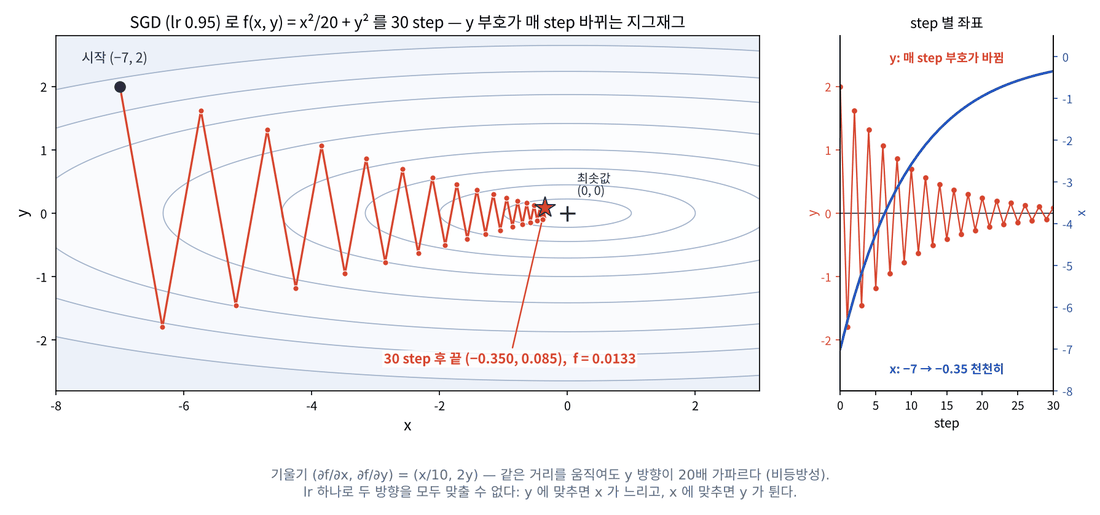

**문제 1-1 · 1-2** 기울기 함수와 SGD 클래스를 만들고, $(-7, 2)$ 에서 30 step 움직인 경로를 구하세요. 오늘의 옵티마이저는 모두 `update(params, grads)` 형태로, `params` 딕셔너리의 배열을 **제자리** 갱신합니다 (Day 3 7교시).

In [ ]:
def grad_f(p):                         # p = [x, y]
    return ____

class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr
    def update(self, params, grads):
        for k in params:
            params[k] -= ____

def run_optimizer(opt, steps=30, start=(-7.0, 2.0)):
    params = {"p": np.array(start, dtype=float)}
    path = [params["p"].copy()]
    for _ in range(steps):
        grads = {"p": ____}
        opt.update(params, grads)
        path.append(params["p"].copy())
    return np.array(path)                  # (steps + 1, 2)

In [ ]:
path = run_optimizer(SGD(lr=0.95))
print("끝점:", path[-1], " y 부호가 바뀐 횟수:", np.sum(np.diff(np.sign(path[:, 1])) != 0))
assert path.shape == (31, 2) and np.allclose(path[-1], [-0.3504, 0.0848], atol=1e-4); print("✅")

def contour(ax):
    g1, g2 = np.meshgrid(np.linspace(-8, 8, 200), np.linspace(-3, 3, 200))
    ax.contour(g1, g2, g1 ** 2 / 20 + g2 ** 2, levels=[0.1, 0.5, 1, 2, 4, 7], colors="gray", linewidths=0.6)
    ax.plot(0, 0, "k+", ms=12)
fig, ax = plt.subplots(figsize=(7, 3)); contour(ax)
ax.plot(path[:, 0], path[:, 1], "o-", ms=3, color="tab:red"); ax.set_title("SGD lr=0.95, 30 steps"); plt.show()

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACmRlZiBncmFkX2YocCk6ICAgICAgICAgICAgICAgICAgICAgICAgICMg"
    "cCA9IFt4LCB5XQogICAgcmV0dXJuIG5wLmFycmF5KFtwWzBdIC8gMTAuMCwgMi4wICogcFsxXV0pCgpjbGFzcyBT"
    "R0Q6CiAgICBkZWYgX19pbml0X18oc2VsZiwgbHI9MC4wMSk6CiAgICAgICAgc2VsZi5sciA9IGxyCiAgICBkZWYg"
    "dXBkYXRlKHNlbGYsIHBhcmFtcywgZ3JhZHMpOgogICAgICAgIGZvciBrIGluIHBhcmFtczoKICAgICAgICAgICAg"
    "cGFyYW1zW2tdIC09IHNlbGYubHIgKiBncmFkc1trXQoKZGVmIHJ1bl9vcHRpbWl6ZXIob3B0LCBzdGVwcz0zMCwg"
    "c3RhcnQ9KC03LjAsIDIuMCkpOgogICAgcGFyYW1zID0geyJwIjogbnAuYXJyYXkoc3RhcnQsIGR0eXBlPWZsb2F0"
    "KX0KICAgIHBhdGggPSBbcGFyYW1zWyJwIl0uY29weSgpXQogICAgZm9yIF8gaW4gcmFuZ2Uoc3RlcHMpOgogICAg"
    "ICAgIGdyYWRzID0geyJwIjogZ3JhZF9mKHBhcmFtc1sicCJdKX0KICAgICAgICBvcHQudXBkYXRlKHBhcmFtcywg"
    "Z3JhZHMpCiAgICAgICAgcGF0aC5hcHBlbmQocGFyYW1zWyJwIl0uY29weSgpKQogICAgcmV0dXJuIG5wLmFycmF5"
    "KHBhdGgpICAgICAgICAgICAgICAgICAgIyAoc3RlcHMgKyAxLCAyKQ=="
).decode("utf-8"))

**문제 1-3** 학습률을 0.1 · 0.95 · 1.0 · 1.05 로 바꿔 끝점을 비교하세요.

$y$ 방향만 보면 한 step 에 $y \leftarrow y - \eta \cdot 2y = (1 - 2\eta)\,y$ 입니다. $|1 - 2\eta| < 1$, 즉 **$\eta < 1$** 이어야 줄어듭니다. 반면 $x$ 방향은 $x \leftarrow (1 - \eta/10)\,x$ 라서 $\eta < 20$ 까지 안정합니다. **가장 가파른 방향이 학습률의 상한을 정하고, 완만한 방향은 그 학습률로는 느리게** 움직일 수밖에 없습니다.

In [ ]:
ends = {}
for lr in [0.1, 0.95, 1.0, 1.05]:
    ends[lr] = ____

In [ ]:
for lr, e in ends.items():
    print(f"lr = {lr:4}:  끝점 ({e[0]:8.3f}, {e[1]:8.3f})   f = {e[0] ** 2 / 20 + e[1] ** 2:10.4f}")
assert np.allclose(ends[0.1], [-5.178, 0.0025], atol=1e-3) and abs(ends[1.0][1]) == 2.0 and abs(ends[1.05][1]) > 30; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACmVuZHMgPSB7fQpmb3IgbHIgaW4gWzAuMSwgMC45NSwgMS4wLCAxLjA1"
    "XToKICAgIGVuZHNbbHJdID0gcnVuX29wdGltaXplcihTR0QobHI9bHIpKVstMV0KCvCfkqEg7ZW07ISkCmxyIDAu"
    "MSDsnYAgeSDripQg6riI67CpIDAg7J20IOuQmOyngOunjCB4IOuKlCAzMCBzdGVwIOyXkCDiiJI3IOKGkiDiiJI1"
    "LjE4IOuwluyXkCDrqrsg6rCR64uI64ukLiBsciAxLjAg7J2AIHkg6rCAICgxIOKIkiAyKcK3eSA9IOKIknkg66Gc"
    "IMKxMiDrpbwg7JiB7JuQ7Z6IIOyYpOqwgOqzoCwgMS4wNSDripQgfDEg4oiSIDIuMXwgPSAxLjEg67Cw7JSpIOy7"
    "pOyguCDrsJzsgrDtlanri4jri6QuIDAuOTUg64qUIOq3uCDsgqzsnbQg4oCUIHkg64qUIOu2gO2YuOulvCDrsJTq"
    "vrjrqbAo7KeA6re47J6s6re4KSDsspzsspztnogg7KSE6rOgIHgg64+EIOyWtOuKkCDsoJXrj4Qg6rCR64uI64uk"
    "LiDslrTrlqQg7ZWZ7Iq166Wg7J2EIOqzqOudvOuPhCDrkZAg67Cp7Zal7J2EIOuPmeyLnOyXkCDrp4zsobHsi5zt"
    "gqTquLAg7Ja066C164uk64qUIOqyg+ydtCBTR0Qg7J2YIOyVveygkOyeheuLiOuLpC4="
).decode("utf-8"))

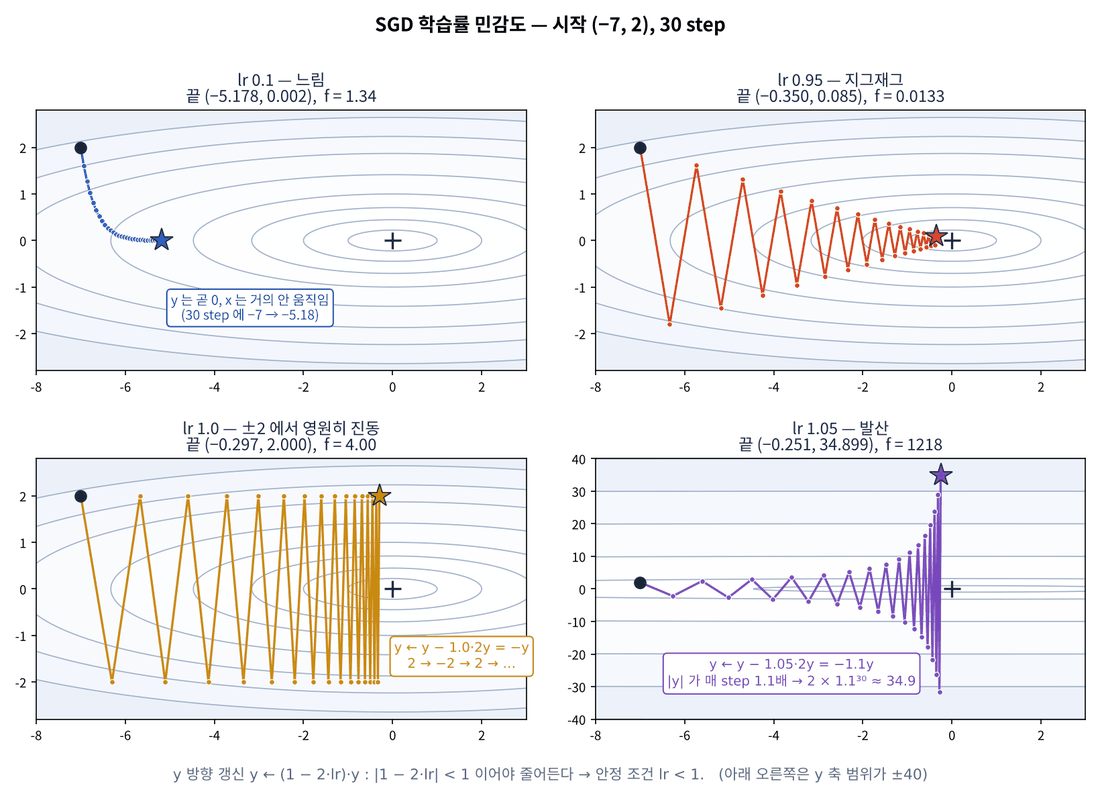

실제 신경망의 손실 지형은 파라미터가 수만 개인 공간에서 이런 비등방성이 훨씬 심합니다. 해결 아이디어는 두 가지입니다.

1. **관성**을 주어 지그재그 성분은 상쇄하고 일관된 방향은 가속한다 → **Momentum**
2. **파라미터마다 학습률을 따로** 조절한다 (많이 움직인 방향은 작게) → **AdaGrad · RMSProp**
3. 둘 다 → **Adam**

#### 📌 1교시 정리

- SGD: $W \leftarrow W - \eta \nabla L$ — 단순하지만 비등방성 지형에서 지그재그.
- 가장 가파른 방향이 학습률 상한을 정한다 ($\eta < 1$), 완만한 방향은 느리다.
- 해결: 관성(Momentum), 파라미터별 학습률(AdaGrad · RMSProp), 둘 다(Adam).

## 2교시 — 옵티마이저 구현

네 가지 옵티마이저를 SGD 와 같은 `update(params, grads)` 형태로 만듭니다. 상태(속도 `v`, 누적 `h`, 모멘트 `m`)는 파라미터마다 따로 필요하므로, 처음 `update` 가 불릴 때 `params` 와 같은 키 · 같은 shape 의 0 배열로 만듭니다.

> 🎬 **애니메이션** [D4-2 옵티마이저 경주](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html#d4-2)  
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html#t2)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

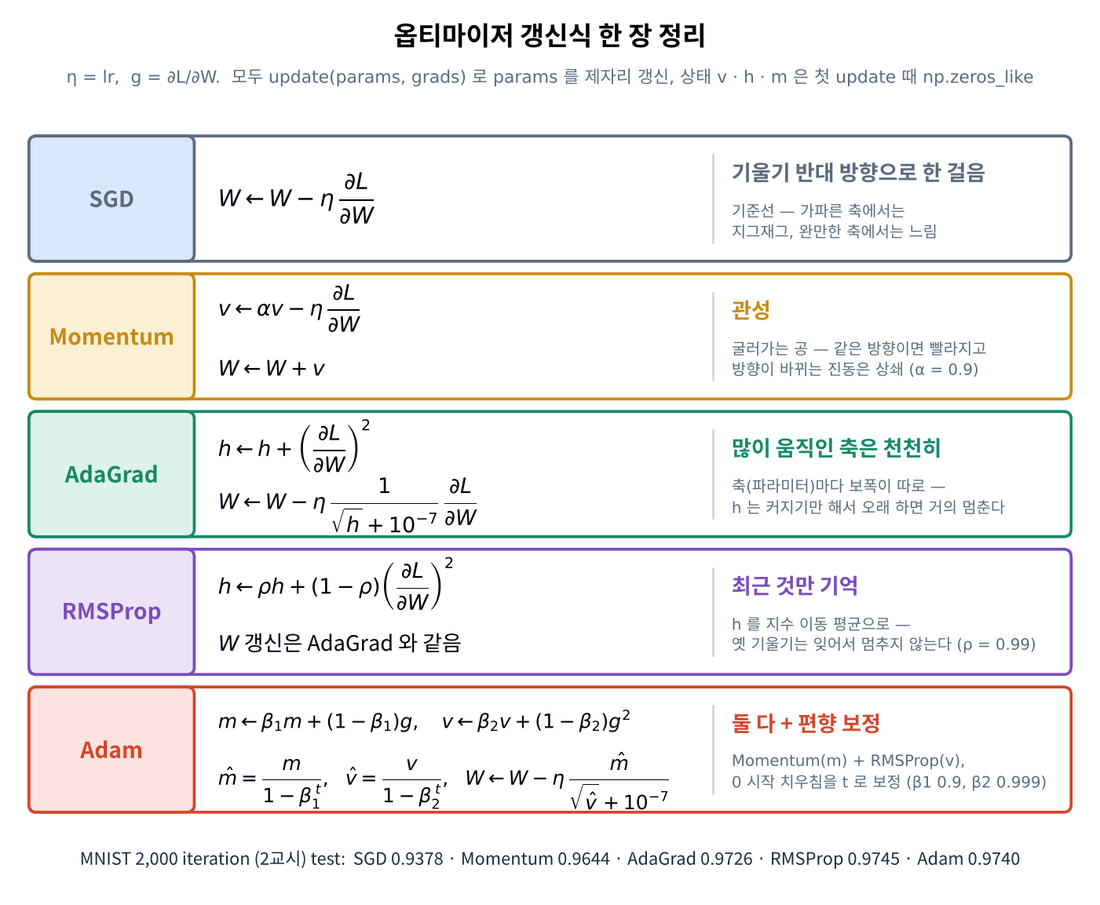

| 옵티마이저 | 갱신식 ($g = \partial L/\partial W$) | 직관 |
|---|---|---|
| **Momentum** | $v \leftarrow \alpha v - \eta g$, $\;W \leftarrow W + v$ ($\alpha = 0.9$) | 공이 굴러가듯 **관성** — 부호가 바뀌는 성분은 상쇄, 일관된 성분은 가속 |
| **AdaGrad** | $h \leftarrow h + g^2$, $\;W \leftarrow W - \eta\,g / (\sqrt{h} + 10^{-7})$ | 많이 움직인 파라미터는 학습률을 **줄인다** (h 는 계속 커짐 → 결국 멈춤) |
| **RMSProp** | $h \leftarrow \rho h + (1 - \rho) g^2$, 나머지 AdaGrad 와 같음 ($\rho = 0.99$) | 오래된 기울기는 **잊는다** (지수 이동 평균) → 멈추지 않음 |
| **Adam** | $m \leftarrow \beta_1 m + (1-\beta_1) g$, $\;v \leftarrow \beta_2 v + (1-\beta_2) g^2$, $\;\hat m = \frac{m}{1-\beta_1^t}$, $\hat v = \frac{v}{1-\beta_2^t}$, $\;W \leftarrow W - \eta\,\hat m / (\sqrt{\hat v} + 10^{-7})$ | Momentum + RMSProp. 처음 몇 step 에 m, v 가 0 쪽으로 치우친 것을 **편향 보정** ($\hat m, \hat v$) |

$10^{-7}$ 은 $h = 0$ 일 때 0 으로 나누지 않으려는 작은 값입니다.

**문제 2-1 ~ 2-4** 네 클래스를 완성하세요.

In [ ]:
class Momentum:
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr, self.momentum, self.v = lr, momentum, None
    def update(self, params, grads):
        if self.v is None:
            self.v = {k: np.zeros_like(p) for k, p in params.items()}
        for k in params:
            self.v[k] = ____
            params[k] += self.v[k]

class AdaGrad:
    def __init__(self, lr=0.01):
        self.lr, self.h = lr, None
    def update(self, params, grads):
        if self.h is None:
            self.h = {k: np.zeros_like(p) for k, p in params.items()}
        for k in params:
            self.h[k] += ____
            params[k] -= self.lr * grads[k] / (____ + 1e-7)

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmNsYXNzIE1vbWVudHVtOgogICAgZGVmIF9faW5pdF9fKHNlbGYsIGxy"
    "PTAuMDEsIG1vbWVudHVtPTAuOSk6CiAgICAgICAgc2VsZi5sciwgc2VsZi5tb21lbnR1bSwgc2VsZi52ID0gbHIs"
    "IG1vbWVudHVtLCBOb25lCiAgICBkZWYgdXBkYXRlKHNlbGYsIHBhcmFtcywgZ3JhZHMpOgogICAgICAgIGlmIHNl"
    "bGYudiBpcyBOb25lOgogICAgICAgICAgICBzZWxmLnYgPSB7azogbnAuemVyb3NfbGlrZShwKSBmb3IgaywgcCBp"
    "biBwYXJhbXMuaXRlbXMoKX0KICAgICAgICBmb3IgayBpbiBwYXJhbXM6CiAgICAgICAgICAgIHNlbGYudltrXSA9"
    "IHNlbGYubW9tZW50dW0gKiBzZWxmLnZba10gLSBzZWxmLmxyICogZ3JhZHNba10KICAgICAgICAgICAgcGFyYW1z"
    "W2tdICs9IHNlbGYudltrXQoKY2xhc3MgQWRhR3JhZDoKICAgIGRlZiBfX2luaXRfXyhzZWxmLCBscj0wLjAxKToK"
    "ICAgICAgICBzZWxmLmxyLCBzZWxmLmggPSBsciwgTm9uZQogICAgZGVmIHVwZGF0ZShzZWxmLCBwYXJhbXMsIGdy"
    "YWRzKToKICAgICAgICBpZiBzZWxmLmggaXMgTm9uZToKICAgICAgICAgICAgc2VsZi5oID0ge2s6IG5wLnplcm9z"
    "X2xpa2UocCkgZm9yIGssIHAgaW4gcGFyYW1zLml0ZW1zKCl9CiAgICAgICAgZm9yIGsgaW4gcGFyYW1zOgogICAg"
    "ICAgICAgICBzZWxmLmhba10gKz0gZ3JhZHNba10gKiogMgogICAgICAgICAgICBwYXJhbXNba10gLT0gc2VsZi5s"
    "ciAqIGdyYWRzW2tdIC8gKG5wLnNxcnQoc2VsZi5oW2tdKSArIDFlLTcp"
).decode("utf-8"))

In [ ]:
class RMSProp:
    def __init__(self, lr=0.01, decay=0.99):
        self.lr, self.decay, self.h = lr, decay, None
    def update(self, params, grads):
        if self.h is None:
            self.h = {k: np.zeros_like(p) for k, p in params.items()}
        for k in params:
            self.h[k] = ____
            params[k] -= self.lr * grads[k] / (np.sqrt(self.h[k]) + 1e-7)

class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999):
        self.lr, self.beta1, self.beta2 = lr, beta1, beta2
        self.m, self.v, self.t = None, None, 0
    def update(self, params, grads):
        if self.m is None:
            self.m = {k: np.zeros_like(p) for k, p in params.items()}
            self.v = {k: np.zeros_like(p) for k, p in params.items()}
        self.t += 1
        for k in params:
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * grads[k]
            self.v[k] = ____
            m_hat = ____        # 편향 보정
            v_hat = ____
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + 1e-7)

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmNsYXNzIFJNU1Byb3A6CiAgICBkZWYgX19pbml0X18oc2VsZiwgbHI9"
    "MC4wMSwgZGVjYXk9MC45OSk6CiAgICAgICAgc2VsZi5sciwgc2VsZi5kZWNheSwgc2VsZi5oID0gbHIsIGRlY2F5"
    "LCBOb25lCiAgICBkZWYgdXBkYXRlKHNlbGYsIHBhcmFtcywgZ3JhZHMpOgogICAgICAgIGlmIHNlbGYuaCBpcyBO"
    "b25lOgogICAgICAgICAgICBzZWxmLmggPSB7azogbnAuemVyb3NfbGlrZShwKSBmb3IgaywgcCBpbiBwYXJhbXMu"
    "aXRlbXMoKX0KICAgICAgICBmb3IgayBpbiBwYXJhbXM6CiAgICAgICAgICAgIHNlbGYuaFtrXSA9IHNlbGYuZGVj"
    "YXkgKiBzZWxmLmhba10gKyAoMSAtIHNlbGYuZGVjYXkpICogZ3JhZHNba10gKiogMgogICAgICAgICAgICBwYXJh"
    "bXNba10gLT0gc2VsZi5sciAqIGdyYWRzW2tdIC8gKG5wLnNxcnQoc2VsZi5oW2tdKSArIDFlLTcpCgpjbGFzcyBB"
    "ZGFtOgogICAgZGVmIF9faW5pdF9fKHNlbGYsIGxyPTAuMDAxLCBiZXRhMT0wLjksIGJldGEyPTAuOTk5KToKICAg"
    "ICAgICBzZWxmLmxyLCBzZWxmLmJldGExLCBzZWxmLmJldGEyID0gbHIsIGJldGExLCBiZXRhMgogICAgICAgIHNl"
    "bGYubSwgc2VsZi52LCBzZWxmLnQgPSBOb25lLCBOb25lLCAwCiAgICBkZWYgdXBkYXRlKHNlbGYsIHBhcmFtcywg"
    "Z3JhZHMpOgogICAgICAgIGlmIHNlbGYubSBpcyBOb25lOgogICAgICAgICAgICBzZWxmLm0gPSB7azogbnAuemVy"
    "b3NfbGlrZShwKSBmb3IgaywgcCBpbiBwYXJhbXMuaXRlbXMoKX0KICAgICAgICAgICAgc2VsZi52ID0ge2s6IG5w"
    "Lnplcm9zX2xpa2UocCkgZm9yIGssIHAgaW4gcGFyYW1zLml0ZW1zKCl9CiAgICAgICAgc2VsZi50ICs9IDEKICAg"
    "ICAgICBmb3IgayBpbiBwYXJhbXM6CiAgICAgICAgICAgIHNlbGYubVtrXSA9IHNlbGYuYmV0YTEgKiBzZWxmLm1b"
    "a10gKyAoMSAtIHNlbGYuYmV0YTEpICogZ3JhZHNba10KICAgICAgICAgICAgc2VsZi52W2tdID0gc2VsZi5iZXRh"
    "MiAqIHNlbGYudltrXSArICgxIC0gc2VsZi5iZXRhMikgKiBncmFkc1trXSAqKiAyCiAgICAgICAgICAgIG1faGF0"
    "ID0gc2VsZi5tW2tdIC8gKDEgLSBzZWxmLmJldGExICoqIHNlbGYudCkgICAgICAgICMg7Y647ZalIOuztOyglQog"
    "ICAgICAgICAgICB2X2hhdCA9IHNlbGYudltrXSAvICgxIC0gc2VsZi5iZXRhMiAqKiBzZWxmLnQpCiAgICAgICAg"
    "ICAgIHBhcmFtc1trXSAtPSBzZWxmLmxyICogbV9oYXQgLyAobnAuc3FydCh2X2hhdCkgKyAxZS03KQ=="
).decode("utf-8"))

**문제 2-5** 다섯 옵티마이저로 같은 함수에서 30 step 을 달리고 끝점을 비교하세요. 학습률은 옵티마이저마다 다르게 정해 두었습니다 (같은 lr 이 같은 의미가 아닙니다).

In [ ]:
optimizers = {"SGD": SGD(lr=0.95), "Momentum": Momentum(lr=0.1), "AdaGrad": AdaGrad(lr=1.5),
              "RMSProp": RMSProp(lr=0.1), "Adam": Adam(lr=0.3)}
paths = {name: ____ for name, opt in optimizers.items()}

In [ ]:
fig, axs = plt.subplots(1, 5, figsize=(18, 3))
for ax, (name, P) in zip(axs, paths.items()):
    contour(ax); ax.plot(P[:, 0], P[:, 1], "o-", ms=2, color="tab:red")
    f_end = P[-1, 0] ** 2 / 20 + P[-1, 1] ** 2
    ax.set_title(f"{name}  f={f_end:.4f}"); ax.set_xlim(-8, 8); ax.set_ylim(-3, 3)
    print(f"{name:8s} 끝점 ({P[-1, 0]:7.3f}, {P[-1, 1]:6.3f})  f = {f_end:.5f}")
plt.show()
assert np.allclose(paths["AdaGrad"][-1], [-0.1202, 0.0], atol=1e-3) and np.allclose(paths["Adam"][-1], [0.1360, 0.3182], atol=1e-3)
assert np.allclose(paths["Momentum"][-1], [0.8964, 0.0881], atol=1e-3); print("✅")

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACm9wdGltaXplcnMgPSB7IlNHRCI6IFNHRChscj0wLjk1KSwgIk1vbWVu"
    "dHVtIjogTW9tZW50dW0obHI9MC4xKSwgIkFkYUdyYWQiOiBBZGFHcmFkKGxyPTEuNSksCiAgICAgICAgICAgICAg"
    "IlJNU1Byb3AiOiBSTVNQcm9wKGxyPTAuMSksICJBZGFtIjogQWRhbShscj0wLjMpfQpwYXRocyA9IHtuYW1lOiBy"
    "dW5fb3B0aW1pemVyKG9wdCkgZm9yIG5hbWUsIG9wdCBpbiBvcHRpbWl6ZXJzLml0ZW1zKCl9"
).decode("utf-8"))

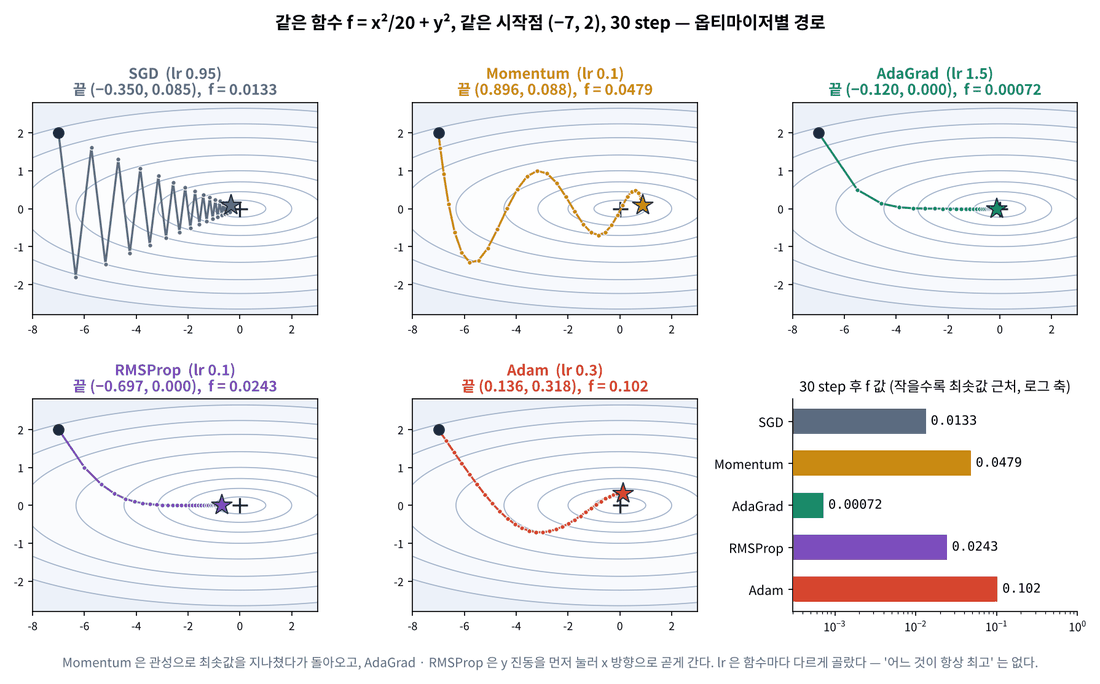

- **Momentum**: 처음엔 SGD 처럼 y 로 튀지만 관성이 x 방향 속도를 쌓아 빠르게 가로지릅니다 (최소점을 지나쳤다가 돌아옴).
- **AdaGrad**: y 방향은 처음 기울기가 커서 $h$ 가 빨리 커지고 → 학습률이 금방 줄어 지그재그가 사라집니다.
- **Adam**: 관성 + 파라미터별 학습률 — 부드러운 곡선으로 접근합니다.

이 함수 하나로 "어느 옵티마이저가 최고"라고 할 수는 없습니다. 실제 신경망에서 비교해 봅니다.

### 실제 신경망에서 — MNIST 5층 MLP

이제부터 실험에 쓸 **`MultiLayerNet`** 과 학습 헬퍼 **`fit`** 입니다. Day 3 의 `TwoLayerNet` 을 은닉층 여러 개로 일반화했고, 오늘 배울 옵션(초기화 · BatchNorm · Dropout · weight decay)이 들어 있습니다. `BatchNorm` 과 `Dropout` 클래스는 4 · 6교시에서 만들고, 그 전에는 옵션을 끈 채로 씁니다.

In [ ]:
def init_scale(weight_init_std, n_in):
    """가중치 표준편차 — 'he': √(2/n_in), 'xavier': √(1/n_in), 숫자: 그대로 (3교시)"""
    if weight_init_std == "he":
        return np.sqrt(2.0 / n_in)
    if weight_init_std == "xavier":
        return np.sqrt(1.0 / n_in)
    return float(weight_init_std)

class MultiLayerNet:
    def __init__(self, input_size, hidden_size_list, output_size, activation="relu", weight_init_std="he",
                 weight_decay_lambda=0.0, use_dropout=False, dropout_ratio=0.5, use_batchnorm=False, seed=0):
        rng_ = np.random.default_rng(seed)
        sizes = [input_size] + list(hidden_size_list) + [output_size]
        self.n_layers = len(sizes) - 1
        self.weight_decay_lambda, self.use_batchnorm = weight_decay_lambda, use_batchnorm
        self.params, self.layers = {}, OrderedDict()
        Act = {"relu": Relu, "sigmoid": Sigmoid}[activation]
        for i in range(1, self.n_layers + 1):
            scale = init_scale(weight_init_std, sizes[i - 1])
            self.params[f"W{i}"] = scale * rng_.standard_normal((sizes[i - 1], sizes[i]))
            self.params[f"b{i}"] = np.zeros(sizes[i])
            self.layers[f"Affine{i}"] = Affine(self.params[f"W{i}"], self.params[f"b{i}"])
            if i < self.n_layers:                                        # 은닉층: [BN] → 활성화 → [Dropout]
                if use_batchnorm:
                    self.params[f"gamma{i}"] = np.ones(sizes[i])
                    self.params[f"beta{i}"] = np.zeros(sizes[i])
                    self.layers[f"BatchNorm{i}"] = BatchNorm(self.params[f"gamma{i}"], self.params[f"beta{i}"])
                self.layers[f"Act{i}"] = Act()
                if use_dropout:
                    self.layers[f"Dropout{i}"] = Dropout(dropout_ratio, seed=seed + i)
        self.lastLayer = SoftmaxWithLoss()

    def predict(self, x, train_flg=False):
        for layer in self.layers.values():
            x = layer.forward(x, train_flg)
        return x

    def loss(self, x, t, train_flg=False):
        L = self.lastLayer.forward(self.predict(x, train_flg), t)
        if self.weight_decay_lambda:                                     # 6교시: + ½λΣW²
            L += 0.5 * self.weight_decay_lambda * sum(np.sum(self.params[f"W{i}"] ** 2) for i in range(1, self.n_layers + 1))
        return L

    def accuracy(self, x, t):
        return np.mean(self.predict(x).argmax(axis=1) == t)

    def gradient(self, x, t):
        self.loss(x, t, train_flg=True)
        dout = self.lastLayer.backward(1)
        for layer in reversed(list(self.layers.values())):
            dout = layer.backward(dout)
        grads = {}
        for i in range(1, self.n_layers + 1):
            a = self.layers[f"Affine{i}"]
            grads[f"W{i}"] = a.dW + self.weight_decay_lambda * self.params[f"W{i}"]   # 6교시: + λW
            grads[f"b{i}"] = a.db
            if self.use_batchnorm and i < self.n_layers:
                grads[f"gamma{i}"] = self.layers[f"BatchNorm{i}"].dgamma
                grads[f"beta{i}"] = self.layers[f"BatchNorm{i}"].dbeta
        return grads

def fit(net, optimizer, X, t, epochs=None, iters=None, batch_size=100, seed=0, X_val=None, t_val=None, eval_every=1):
    """미니배치 학습 (Day 3 7교시 루프). epochs 또는 iters 로 길이를 정한다. eval_every epoch 마다 정확도 기록."""
    rng_ = np.random.default_rng(seed)
    N = len(X); ipe = max(N // batch_size, 1)
    total = iters if iters else epochs * ipe
    h = {"loss": [], "epoch": [], "train_acc": [], "val_acc": [], "val_loss": []}
    it, epoch = 0, 0
    while it < total:
        idx = rng_.permutation(N); epoch += 1
        for i in range(ipe):
            batch = idx[i * batch_size:(i + 1) * batch_size]
            optimizer.update(net.params, net.gradient(X[batch], t[batch]))
            h["loss"].append(float(net.lastLayer.loss)); it += 1
            if it >= total:
                break
        if eval_every and epoch % eval_every == 0:
            h["epoch"].append(epoch); h["train_acc"].append(net.accuracy(X, t))
            if X_val is not None:
                h["val_acc"].append(net.accuracy(X_val, t_val))
                h["val_loss"].append(net.lastLayer.forward(net.predict(X_val), t_val))
    return h

print("MultiLayerNet · fit 준비 완료")

**문제 2-6** 784-100-100-100-100-10 (He 초기화) 을 다섯 옵티마이저로 2000 iteration (배치 128) 씩 학습해 손실 곡선과 test 정확도를 비교하세요. 옵티마이저마다 약 6초, 모두 30초쯤 걸립니다.

In [ ]:
opt_makers = {"SGD": lambda: SGD(lr=0.01), "Momentum": lambda: Momentum(lr=0.01), "AdaGrad": lambda: AdaGrad(lr=0.01),
              "RMSProp": lambda: RMSProp(lr=0.001), "Adam": lambda: Adam(lr=0.001)}
curves, test_acc = {}, {}
for name, make in opt_makers.items():
    net = MultiLayerNet(784, [100, 100, 100, 100], 10, weight_init_std="he")
    h = ____
    curves[name] = h["loss"]
    test_acc[name] = ____
    print(f"{name:8s} 마지막 100 iteration 평균 손실 {np.mean(h['loss'][-100:]):.3f}   test {test_acc[name]:.4f}")

In [ ]:
smooth = lambda y, k=50: np.convolve(y, np.ones(k) / k, mode="valid")
for name, c in curves.items():
    plt.plot(smooth(c), label=f"{name} ({test_acc[name]:.3f})")
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("loss (smoothed)"); plt.legend(); plt.grid(alpha=.3); plt.show()
assert test_acc["SGD"] < test_acc["Momentum"] < test_acc["Adam"] and test_acc["Adam"] > 0.97; print("✅ SGD 가 가장 느림")

In [ ]:
#@title 🔒 정답 보기 2-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTQg4pSA4pSACm9wdF9tYWtlcnMgPSB7IlNHRCI6IGxhbWJkYTogU0dEKGxyPTAuMDEp"
    "LCAiTW9tZW50dW0iOiBsYW1iZGE6IE1vbWVudHVtKGxyPTAuMDEpLCAiQWRhR3JhZCI6IGxhbWJkYTogQWRhR3Jh"
    "ZChscj0wLjAxKSwKICAgICAgICAgICAgICAiUk1TUHJvcCI6IGxhbWJkYTogUk1TUHJvcChscj0wLjAwMSksICJB"
    "ZGFtIjogbGFtYmRhOiBBZGFtKGxyPTAuMDAxKX0KY3VydmVzLCB0ZXN0X2FjYyA9IHt9LCB7fQpmb3IgbmFtZSwg"
    "bWFrZSBpbiBvcHRfbWFrZXJzLml0ZW1zKCk6CiAgICBuZXQgPSBNdWx0aUxheWVyTmV0KDc4NCwgWzEwMCwgMTAw"
    "LCAxMDAsIDEwMF0sIDEwLCB3ZWlnaHRfaW5pdF9zdGQ9ImhlIikKICAgIGggPSBmaXQobmV0LCBtYWtlKCksIFhf"
    "dHJhaW4sIHRfdHJhaW4sIGl0ZXJzPTIwMDAsIGJhdGNoX3NpemU9MTI4LCBldmFsX2V2ZXJ5PU5vbmUpCiAgICBj"
    "dXJ2ZXNbbmFtZV0gPSBoWyJsb3NzIl0KICAgIHRlc3RfYWNjW25hbWVdID0gbmV0LmFjY3VyYWN5KFhfdGVzdCwg"
    "dF90ZXN0KQogICAgcHJpbnQoZiJ7bmFtZTo4c30g66eI7KeA66eJIDEwMCBpdGVyYXRpb24g7Y+J6regIOyGkOyL"
    "pCB7bnAubWVhbihoWydsb3NzJ11bLTEwMDpdKTouM2Z9ICAgdGVzdCB7dGVzdF9hY2NbbmFtZV06LjRmfSIp"
).decode("utf-8"))

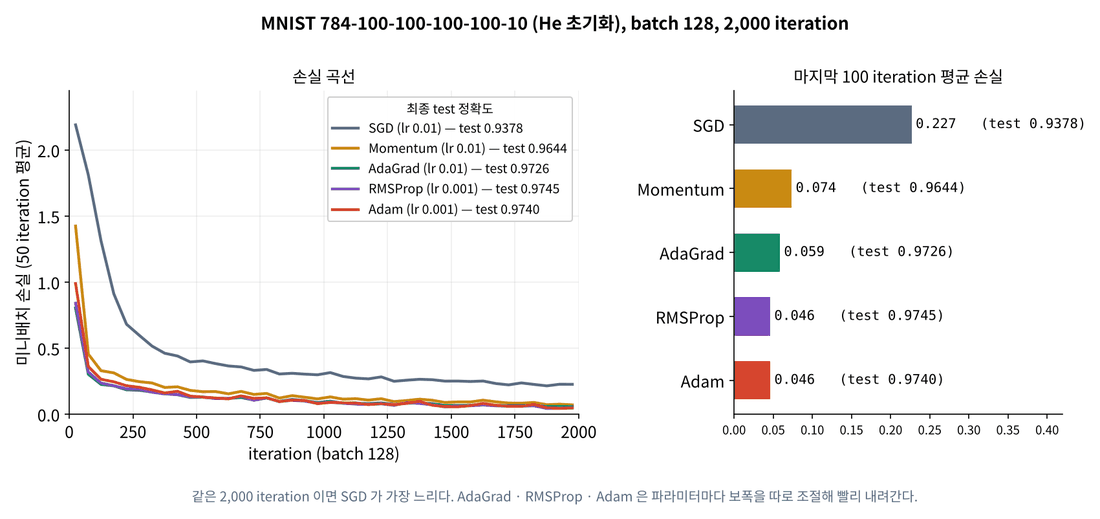

같은 2000 iteration 에서 SGD(0.9378)는 가장 느리고, Momentum(0.9644), AdaGrad(0.9726), RMSProp(0.9745), Adam(0.9740)은 훨씬 빠르게 손실을 줄입니다. 실무에서는 **Adam 을 기본값**으로 쓰고 (lr 0.001 부근), 마지막 성능을 짜낼 때 SGD + Momentum 을 다시 시도하기도 합니다. 8교시 프로젝트는 Adam 을 씁니다.

#### ⚠️ 자주 하는 실수

- 상태를 `__init__` 에서 만들려고 하면 파라미터 shape 를 모릅니다 → 처음 `update` 때 `zeros_like`.
- `params[k] = params[k] - ...` — 새 배열이 생겨 계층(Affine)과 연결이 끊깁니다 (Day 3). `-=`, `+=` 로 제자리 갱신.
- Adam 의 `self.t += 1` 을 파라미터 for 문 **안**에 넣으면 파라미터 개수만큼 t 가 커져 편향 보정이 틀어집니다.
- 옵티마이저 객체를 여러 모델에 재사용 — 상태(v, h, m)가 섞입니다. 모델마다 새로 만드세요.

#### 📌 2교시 정리

- Momentum = 관성, AdaGrad = 파라미터별 학습률(누적), RMSProp = 지수 이동 평균, Adam = 둘 다 + 편향 보정.
- 모두 `update(params, grads)` 로 제자리 갱신, 상태는 파라미터와 같은 shape.
- MNIST: SGD 0.9378 < Momentum 0.9644 < AdaGrad · RMSProp · Adam ≈ 0.973 (2000 iteration).

## 3교시 — 가중치 초기화

학습은 초기 가중치에서 출발합니다. Day 3 는 `0.01 × 정규분포`로 시작했고 2층에서는 문제없었습니다. 층이 깊어지면 어떻게 될까요?

> 🎬 **애니메이션** [D4-3 가중치 초기화 · 활성화 분포](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html#d4-3)  
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html#t3)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

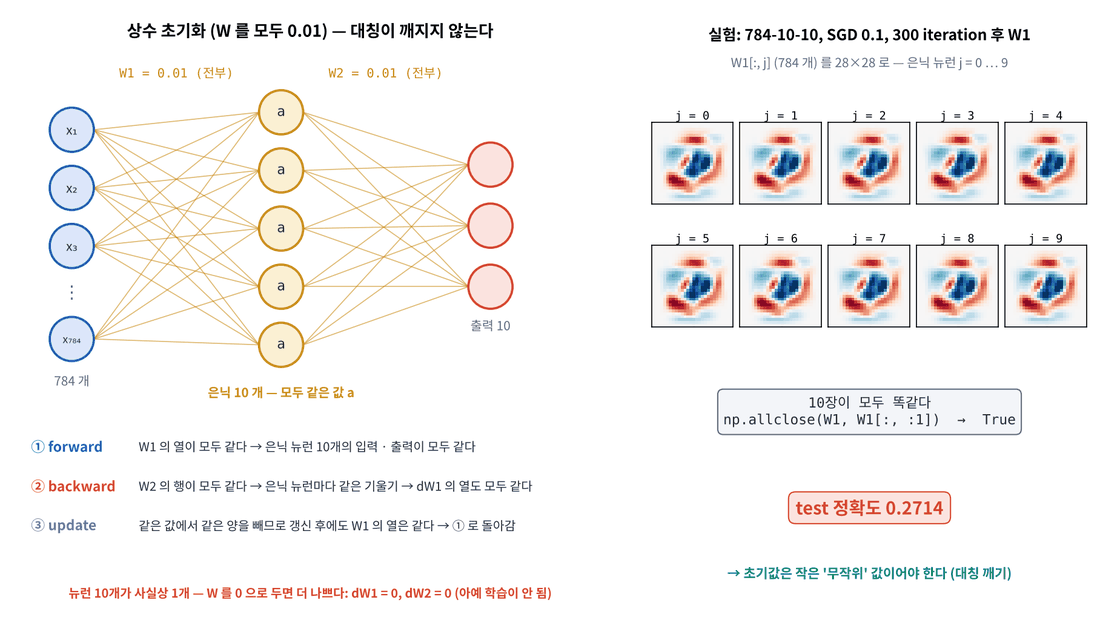

### 모두 같은 값(0)으로 시작하면?

가중치가 모두 같으면 은닉 뉴런들은 같은 입력에 같은 가중치를 곱하므로 **같은 값**을 내고, 역전파 때 **같은 기울기**를 받아 **같이** 갱신됩니다. 100개를 두어도 사실상 1개입니다 — **대칭성(symmetry)** 이 깨지지 않습니다. (모두 0 이면 더 나쁩니다: ReLU 출력이 0 이라 기울기 자체가 0.)

In [ ]:
net_c = MultiLayerNet(784, [10], 10, weight_init_std=0.0)          # 모두 0 으로 만든 뒤
g0 = net_c.gradient(X_train[:100], t_train[:100])
print("모두 0: |dW1| 최대", np.abs(g0["W1"]).max(), " |dW2| 최대", np.abs(g0["W2"]).max())

net_c.params["W1"][...] = 0.01; net_c.params["W2"][...] = 0.01      # 모두 0.01 (상수)
fit(net_c, SGD(lr=0.1), X_train, t_train, iters=300, eval_every=None)
W1 = net_c.params["W1"]
print("모두 0.01 로 300 iteration 학습 후 — W1 의 10개 열이 모두 같은가?", np.allclose(W1, W1[:, :1]),
      " test", net_c.accuracy(X_test, t_test))

### 활성화 값의 분포 — 층을 지날수록 어떻게 변하나

입력 1000개(100차원 정규분포)를 100 노드짜리 층 5개에 통과시키며 **활성화 값의 히스토그램**을 봅니다. 좋은 초기화는 층을 지나도 활성화가 **적당히 퍼진 분포를 유지**합니다.

| 문제 | 증상 | 결과 |
|---|---|---|
| 가중치가 너무 큼 (sigmoid, std 1) | 활성화가 0 과 1 에 몰림 | 그 지점의 sigmoid 기울기 ≈ 0 → **기울기 소실** (Day 2) |
| 가중치가 너무 작음 (std 0.01) | 모두 0.5 근처(sigmoid) 또는 0 근처(ReLU) | 뉴런들이 같은 값 → **표현력 제한**, ReLU 는 신호가 사라짐 |

해결은 **입력 노드 수 $n$ 에 맞춰 표준편차를 정하는 것**입니다. 출력의 분산은 대략 $n \times \text{Var}(W) \times \text{Var}(x)$ 이므로 $\text{Var}(W) = 1/n$ 이면 층을 지나도 분산이 유지됩니다.

- **Xavier** (sigmoid · tanh): $\text{std} = \sqrt{1/n}$
- **He** (ReLU): $\text{std} = \sqrt{2/n}$ — ReLU 는 음수 절반을 0 으로 만들어 분산이 반으로 줄기 때문에 2 배.

**문제 3-1 · 3-2** Xavier · He 표준편차 함수를 만들고, 활성화 분포 실험 루프를 완성하세요.

In [ ]:
def xavier_std(n_in):
    return ____

def he_std(n_in):
    return ____

def activation_stats(weight_init_std, act, n_layers=5, seed=0):
    rng_ = np.random.default_rng(seed)
    x = rng_.standard_normal((1000, 100))
    outs = []
    for _ in range(n_layers):
        W = init_scale(weight_init_std, 100) * rng_.standard_normal((100, 100))
        a = ____
        x = ____
        outs.append(x)
    return outs

In [ ]:
assert np.isclose(xavier_std(100), 0.1) and np.isclose(he_std(784), init_scale("he", 784))
for act, inits in [("sigmoid", [1.0, 0.01, "xavier"]), ("relu", [0.01, "xavier", "he"])]:
    fig, axs = plt.subplots(len(inits), 5, figsize=(14, 2.2 * len(inits)))
    for r, w in enumerate(inits):
        outs = activation_stats(w, act)
        for c, a in enumerate(outs):
            vals = a.ravel() if act == "sigmoid" else a[a > 0].ravel()
            axs[r, c].hist(vals, bins=30, range=(0, 1) if act == "sigmoid" else None)
            axs[r, c].set_title(f"{act} {w} L{c + 1} std={a.std():.3f}", fontsize=8); axs[r, c].set_yticks([])
        print(f"{act:7s} {str(w):6s} 층별 표준편차:", np.round([a.std() for a in outs], 4))
    plt.tight_layout(); plt.show()
s1 = activation_stats(1.0, "sigmoid")
assert np.isclose(np.mean((s1[0] < 0.1) | (s1[0] > 0.9)), 0.82, atol=0.01)
assert activation_stats("he", "relu")[-1].std() > 0.9 and activation_stats(0.01, "relu")[-1].std() < 1e-4; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACmRlZiB4YXZpZXJfc3RkKG5faW4pOgogICAgcmV0dXJuIG5wLnNxcnQo"
    "MS4wIC8gbl9pbikKCmRlZiBoZV9zdGQobl9pbik6CiAgICByZXR1cm4gbnAuc3FydCgyLjAgLyBuX2luKQoKZGVm"
    "IGFjdGl2YXRpb25fc3RhdHMod2VpZ2h0X2luaXRfc3RkLCBhY3QsIG5fbGF5ZXJzPTUsIHNlZWQ9MCk6CiAgICBy"
    "bmdfID0gbnAucmFuZG9tLmRlZmF1bHRfcm5nKHNlZWQpCiAgICB4ID0gcm5nXy5zdGFuZGFyZF9ub3JtYWwoKDEw"
    "MDAsIDEwMCkpCiAgICBvdXRzID0gW10KICAgIGZvciBfIGluIHJhbmdlKG5fbGF5ZXJzKToKICAgICAgICBXID0g"
    "aW5pdF9zY2FsZSh3ZWlnaHRfaW5pdF9zdGQsIDEwMCkgKiBybmdfLnN0YW5kYXJkX25vcm1hbCgoMTAwLCAxMDAp"
    "KQogICAgICAgIGEgPSB4IEAgVwogICAgICAgIHggPSAxIC8gKDEgKyBucC5leHAoLWEpKSBpZiBhY3QgPT0gInNp"
    "Z21vaWQiIGVsc2UgbnAubWF4aW11bSgwLCBhKQogICAgICAgIG91dHMuYXBwZW5kKHgpCiAgICByZXR1cm4gb3V0"
    "cw=="
).decode("utf-8"))

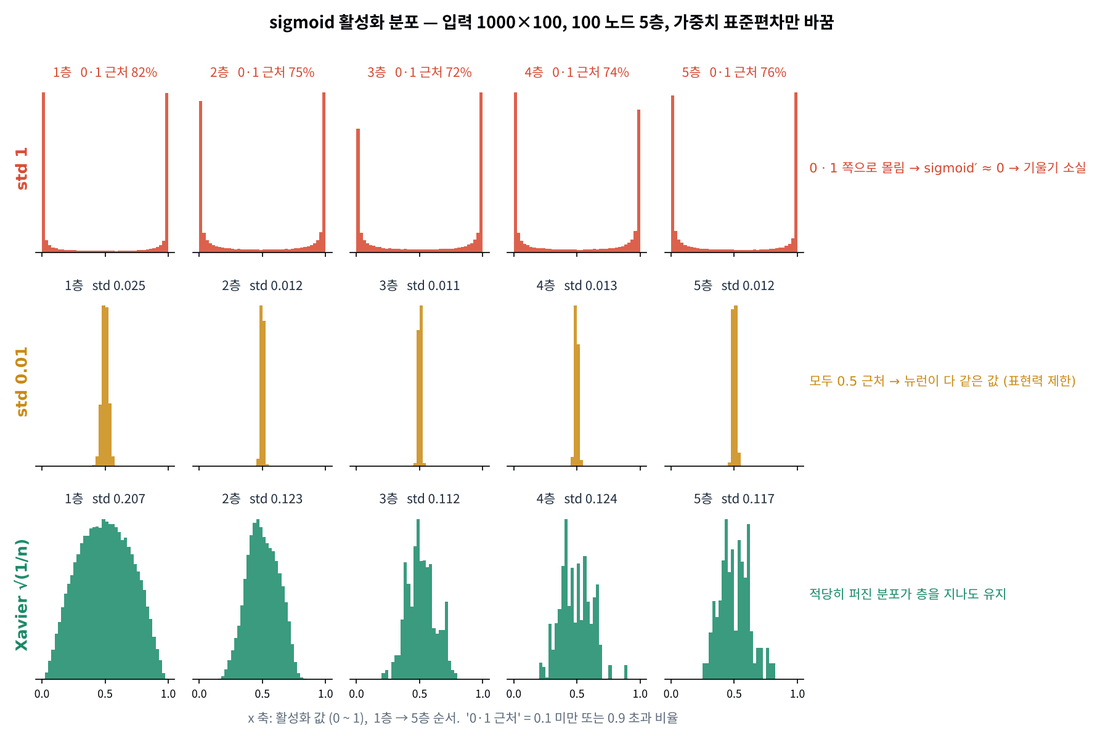

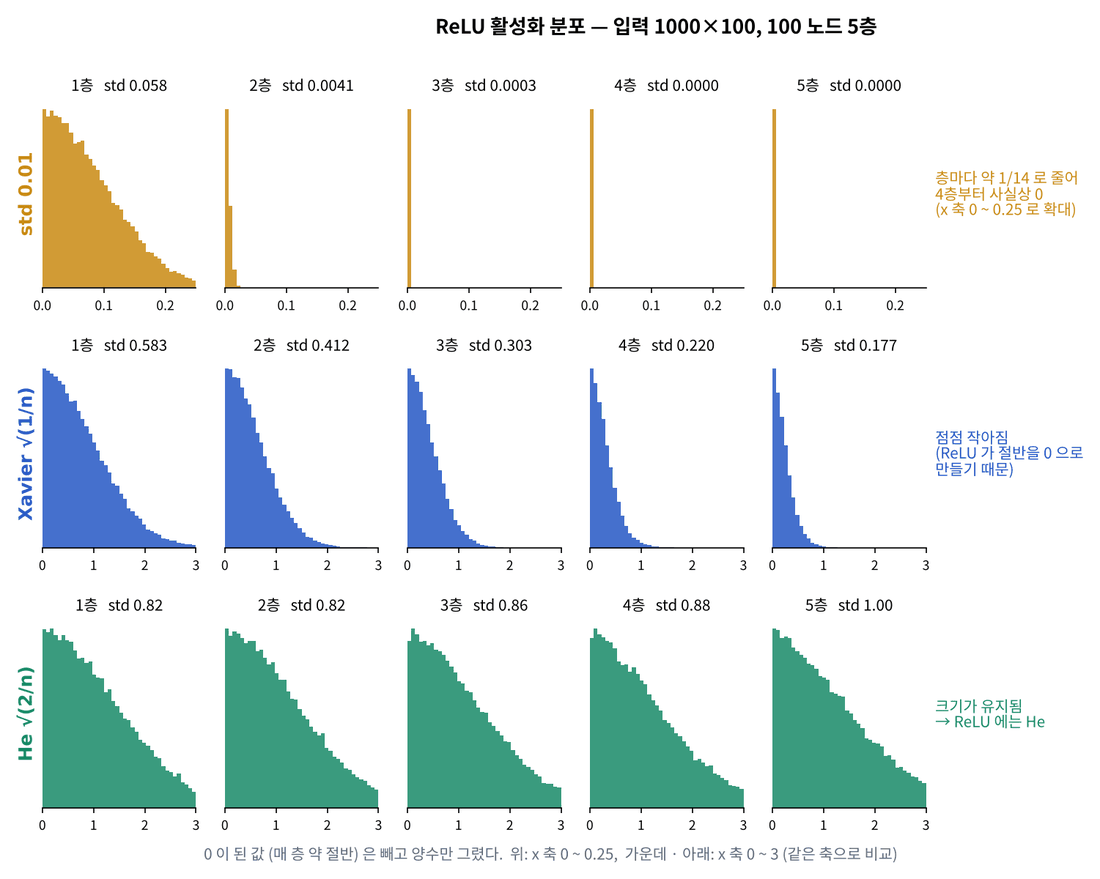

- sigmoid + std 1: 활성화의 약 **75~82%** 가 0.1 미만이나 0.9 초과 — 기울기 소실 지대.
- ReLU + std 0.01: 표준편차가 0.058 → 0.004 → 0.0003 → … 층마다 **사라집니다**.
- ReLU + Xavier: 0.58 → 0.18 로 점점 줄어듦. ReLU + **He**: 0.82 → 1.00 으로 **유지**.

**문제 3-3** MNIST 4층 은닉 MLP 를 std 0.01 · Xavier · He 로 각각 SGD(0.01) 2000 iteration 학습해 비교하세요.

In [ ]:
init_curves, init_acc = {}, {}
for w in [0.01, "xavier", "he"]:
    net = ____
    h = fit(net, SGD(lr=0.01), X_train, t_train, iters=2000, batch_size=128, eval_every=None)
    init_curves[str(w)], init_acc[str(w)] = h["loss"], net.accuracy(X_test, t_test)
    print(f"{str(w):7s} 마지막 손실 {np.mean(h['loss'][-100:]):.3f}  test {init_acc[str(w)]:.4f}")

In [ ]:
for w, c in init_curves.items():
    plt.plot(smooth(c), label=f"std {w} ({init_acc[w]:.3f})")
plt.xlabel("iteration"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=.3); plt.show()
assert init_acc["0.01"] < 0.2 and init_acc["he"] > init_acc["xavier"] > 0.9; print("✅ std 0.01 은 깊은 망에서 학습이 시작조차 안 됨")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmluaXRfY3VydmVzLCBpbml0X2FjYyA9IHt9LCB7fQpmb3IgdyBpbiBb"
    "MC4wMSwgInhhdmllciIsICJoZSJdOgogICAgbmV0ID0gTXVsdGlMYXllck5ldCg3ODQsIFsxMDAsIDEwMCwgMTAw"
    "LCAxMDBdLCAxMCwgd2VpZ2h0X2luaXRfc3RkPXcpCiAgICBoID0gZml0KG5ldCwgU0dEKGxyPTAuMDEpLCBYX3Ry"
    "YWluLCB0X3RyYWluLCBpdGVycz0yMDAwLCBiYXRjaF9zaXplPTEyOCwgZXZhbF9ldmVyeT1Ob25lKQogICAgaW5p"
    "dF9jdXJ2ZXNbc3RyKHcpXSwgaW5pdF9hY2Nbc3RyKHcpXSA9IGhbImxvc3MiXSwgbmV0LmFjY3VyYWN5KFhfdGVz"
    "dCwgdF90ZXN0KQogICAgcHJpbnQoZiJ7c3RyKHcpOjdzfSDrp4jsp4Drp4kg7IaQ7IukIHtucC5tZWFuKGhbJ2xv"
    "c3MnXVstMTAwOl0pOi4zZn0gIHRlc3Qge2luaXRfYWNjW3N0cih3KV06LjRmfSIpCgrwn5KhIO2VtOyEpApzdGQg"
    "MC4wMSDsnYAg7IaQ7Iuk7J20IDIuMzAgKD0gbG4gMTAsIOq3oOuTsSDtmZXrpaAp7JeQ7IScIOqxsOydmCDsm4Ds"
    "p4HsnbTsp4Ag7JWK7Iq164uI64ukLiDsi6DtmLjqsIAg7Li166eI64ukIDEvMTAg7J207ZWY66GcIOykhOyWtCDs"
    "tpzroKXsnbQgMCDqt7zsspgsIOyXreuwqe2WpSDquLDsmrjquLDrj4Qg6rCZ7J2AIOu5hOycqOuhnCDspITslrQg"
    "7JWe7Kq9IOy4teydgCDsgqzsi6Tsg4Eg7ZWZ7Iq165CY7KeAIOyViuyKteuLiOuLpC4gRGF5IDMg7J2YIDLsuLUg"
    "66ed7J2AIOy4teydtCDsoIHslrQgMC4wMSDroZzrj4Qg6rSc7LCu7JWY642YIOqyg+yeheuLiOuLpC4gUmVMVSDr"
    "p53sl5DripQgSGUg6rCAIFhhdmllciDrs7Tri6Qg67mg66aF64uI64ukLg=="
).decode("utf-8"))

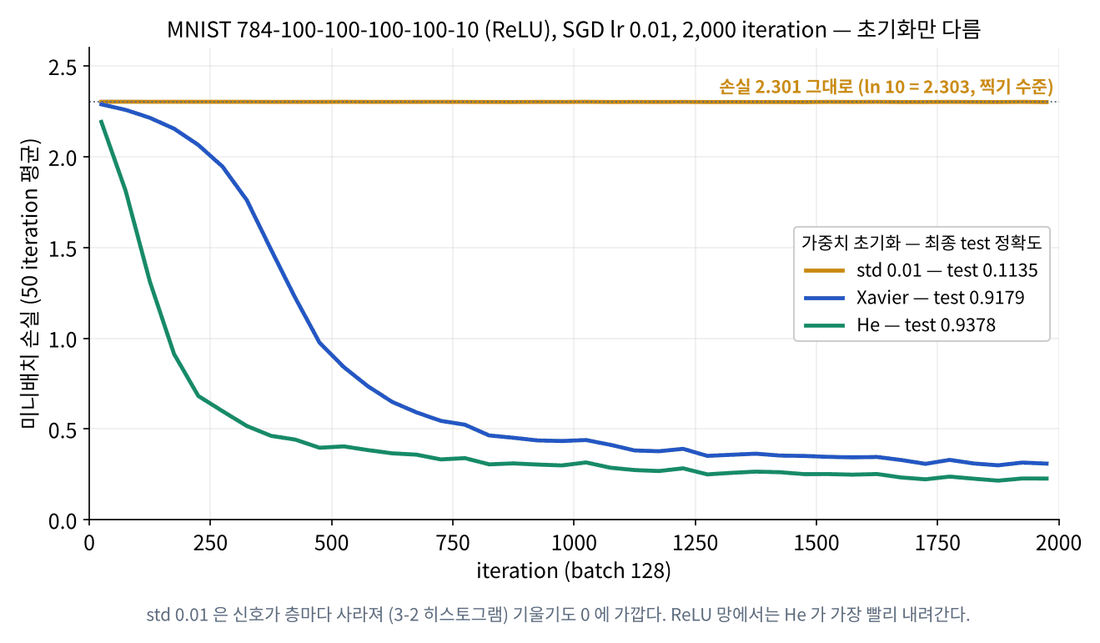

#### ⚠️ 자주 하는 실수

- 모든 가중치를 0(또는 같은 값)으로 초기화 — 대칭이 깨지지 않습니다. 편향은 0 이어도 괜찮습니다 (가중치가 이미 다르므로).
- He 의 $n$ 을 **출력** 노드 수로 — 입력 노드 수(이전 층 뉴런 수) $n_{in}$ 입니다.
- sigmoid 망에 He, ReLU 망에 Xavier — 짝을 맞추세요. (틀려도 학습은 되지만 느리거나 불안정)

#### 📌 3교시 정리

- 같은 값으로 초기화하면 대칭 → 뉴런이 모두 같아진다. 무작위가 필요.
- 너무 크면 포화(기울기 소실), 너무 작으면 신호 소멸.
- Xavier $\sqrt{1/n}$ (sigmoid), **He $\sqrt{2/n}$ (ReLU)**. MNIST 4층: 0.01 → 0.11, Xavier → 0.92, He → 0.94.

## 4교시 — Batch Normalization

초기화는 **출발점**에서만 분포를 맞춥니다. 학습이 진행되면 가중치가 바뀌어 분포가 다시 틀어집니다. **Batch Normalization (BN)** 은 매 미니배치마다 층의 출력을 **강제로** 평균 0 · 분산 1 로 맞춥니다.

> 🎬 **애니메이션** [D4-4 Batch Normalization](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html#d4-4)  
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html#t4)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

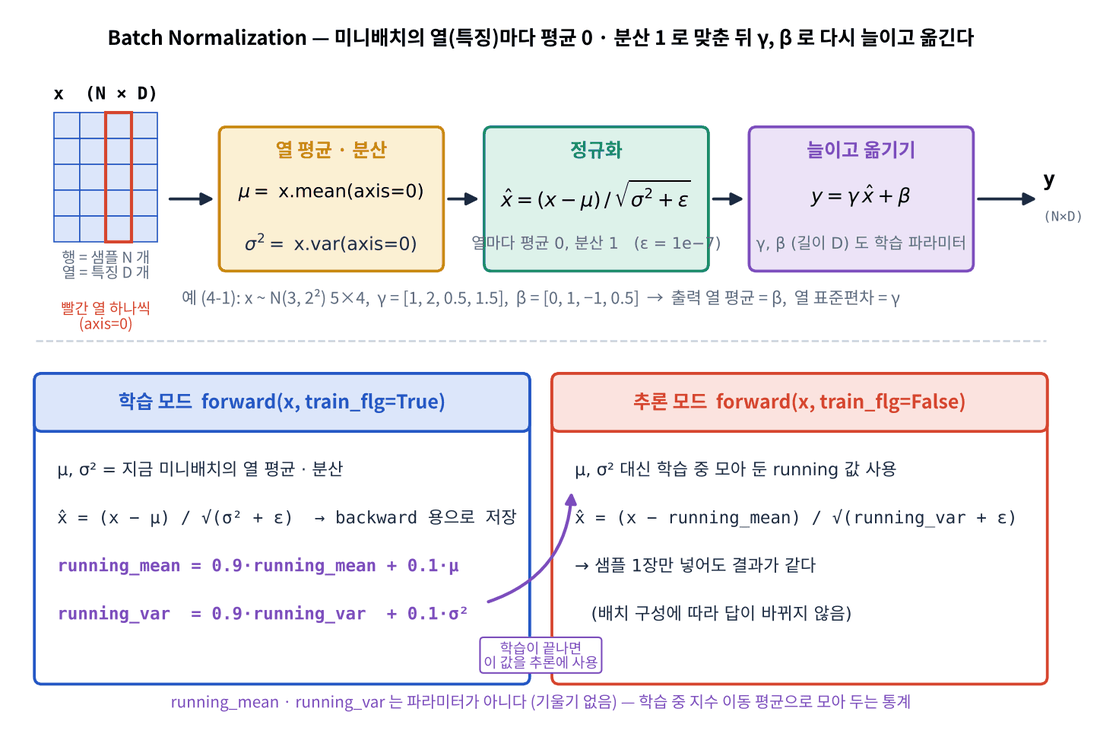

미니배치 $x$ (N, D) 의 **열(특성)마다**:

$$\mu = \frac{1}{N}\sum_i x_i, \qquad \sigma^2 = \frac{1}{N}\sum_i (x_i - \mu)^2, \qquad \hat x = \frac{x - \mu}{\sqrt{\sigma^2 + \varepsilon}}, \qquad y = \gamma \hat x + \beta$$

- $\varepsilon = 10^{-7}$: 분산이 0 일 때를 대비한 작은 값.
- **γ (scale), β (shift)** 는 학습되는 파라미터 (처음 1, 0). "평균 0 · 분산 1 이 최선이 아니면 네트워크가 스스로 늘이고 옮겨라."
- **추론 때**는 미니배치가 없을 수도 있고(사진 한 장), 결과가 배치 구성에 따라 달라지면 안 됩니다. 그래서 학습 중에 **이동 평균** `running_mean = 0.9·running_mean + 0.1·μ` (분산도) 을 모아 두고 추론 때 그것을 씁니다 → `train_flg` 가 필요한 이유.

BN 계층은 보통 **Affine → BN → ReLU** 순서로 넣습니다.

**문제 4-1** `BatchNorm.forward` 를 완성하세요.

In [ ]:
class BatchNorm:
    def __init__(self, gamma, beta, momentum=0.9, eps=1e-7):
        self.gamma, self.beta = gamma, beta              # 바깥 params 와 같은 배열
        self.momentum, self.eps = momentum, eps
        self.running_mean, self.running_var = None, None

    def forward(self, x, train_flg=True):
        if self.running_mean is None:
            self.running_mean, self.running_var = np.zeros(x.shape[1]), np.ones(x.shape[1])
        if train_flg:
            mu = ____
            xc = x - mu
            var = ____
            std = np.sqrt(var + self.eps)
            xn = ____
            self.xc, self.xn, self.std = xc, xn, std     # backward 용
            self.running_mean = ____
            self.running_var = self.momentum * self.running_var + (1 - self.momentum) * var
        else:
            xn = ____
        return self.gamma * xn + self.beta

    def backward(self, dout):                            # 문제 4-2 에서 완성
        raise NotImplementedError

In [ ]:
rng4 = np.random.default_rng(4)
xb = rng4.normal(3.0, 2.0, size=(5, 4))                  # 평균 3, 표준편차 2 근처인 미니배치 5개
gamma_ex, beta_ex = np.array([1.0, 2.0, 0.5, 1.5]), np.array([0.0, 1.0, -1.0, 0.5])
bn = BatchNorm(gamma_ex, beta_ex)
yb = bn.forward(xb)
print("입력 열 평균", xb.mean(axis=0), "\n출력 열 평균", yb.mean(axis=0).round(6), " (= β)\n출력 열 표준편차", yb.std(axis=0).round(4), " (= γ)")
assert np.allclose(yb.mean(axis=0), beta_ex) and np.allclose(yb.std(axis=0), gamma_ex, atol=1e-6); print("✅")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmNsYXNzIEJhdGNoTm9ybToKICAgIGRlZiBfX2luaXRfXyhzZWxmLCBn"
    "YW1tYSwgYmV0YSwgbW9tZW50dW09MC45LCBlcHM9MWUtNyk6CiAgICAgICAgc2VsZi5nYW1tYSwgc2VsZi5iZXRh"
    "ID0gZ2FtbWEsIGJldGEgICAgICAgICAgICAgICMg67CU6rmlIHBhcmFtcyDsmYAg6rCZ7J2AIOuwsOyXtAogICAg"
    "ICAgIHNlbGYubW9tZW50dW0sIHNlbGYuZXBzID0gbW9tZW50dW0sIGVwcwogICAgICAgIHNlbGYucnVubmluZ19t"
    "ZWFuLCBzZWxmLnJ1bm5pbmdfdmFyID0gTm9uZSwgTm9uZQoKICAgIGRlZiBmb3J3YXJkKHNlbGYsIHgsIHRyYWlu"
    "X2ZsZz1UcnVlKToKICAgICAgICBpZiBzZWxmLnJ1bm5pbmdfbWVhbiBpcyBOb25lOgogICAgICAgICAgICBzZWxm"
    "LnJ1bm5pbmdfbWVhbiwgc2VsZi5ydW5uaW5nX3ZhciA9IG5wLnplcm9zKHguc2hhcGVbMV0pLCBucC5vbmVzKHgu"
    "c2hhcGVbMV0pCiAgICAgICAgaWYgdHJhaW5fZmxnOgogICAgICAgICAgICBtdSA9IHgubWVhbihheGlzPTApCiAg"
    "ICAgICAgICAgIHhjID0geCAtIG11CiAgICAgICAgICAgIHZhciA9IG5wLm1lYW4oeGMgKiogMiwgYXhpcz0wKQog"
    "ICAgICAgICAgICBzdGQgPSBucC5zcXJ0KHZhciArIHNlbGYuZXBzKQogICAgICAgICAgICB4biA9IHhjIC8gc3Rk"
    "CiAgICAgICAgICAgIHNlbGYueGMsIHNlbGYueG4sIHNlbGYuc3RkID0geGMsIHhuLCBzdGQgICAgICMgYmFja3dh"
    "cmQg7JqpCiAgICAgICAgICAgIHNlbGYucnVubmluZ19tZWFuID0gc2VsZi5tb21lbnR1bSAqIHNlbGYucnVubmlu"
    "Z19tZWFuICsgKDEgLSBzZWxmLm1vbWVudHVtKSAqIG11CiAgICAgICAgICAgIHNlbGYucnVubmluZ192YXIgPSBz"
    "ZWxmLm1vbWVudHVtICogc2VsZi5ydW5uaW5nX3ZhciArICgxIC0gc2VsZi5tb21lbnR1bSkgKiB2YXIKICAgICAg"
    "ICBlbHNlOgogICAgICAgICAgICB4biA9ICh4IC0gc2VsZi5ydW5uaW5nX21lYW4pIC8gbnAuc3FydChzZWxmLnJ1"
    "bm5pbmdfdmFyICsgc2VsZi5lcHMpCiAgICAgICAgcmV0dXJuIHNlbGYuZ2FtbWEgKiB4biArIHNlbGYuYmV0YQoK"
    "ICAgIGRlZiBiYWNrd2FyZChzZWxmLCBkb3V0KTogICAgICAgICAgICAgICAgICAgICAgICAgICAgIyDrrLjsoJwg"
    "NC0yIOyXkOyEnCDsmYTshLEKICAgICAgICByYWlzZSBOb3RJbXBsZW1lbnRlZEVycm9y"
).decode("utf-8"))

**문제 4-2** `backward` 를 완성하세요. 계산 그래프로 유도하면(평균 · 분산이 모든 $x_i$ 에 의존하므로 경로가 여러 개) 다음 식으로 정리됩니다 ($d\hat x = \gamma \cdot \text{dout}$).

$$d\beta = \sum_i \text{dout}_i, \qquad d\gamma = \sum_i \hat x_i \,\text{dout}_i, \qquad dx = \frac{N\,d\hat x - \sum_i d\hat x_i - \hat x \sum_i (d\hat x_i\, \hat x_i)}{N \cdot \text{std}}$$

뒤의 두 항은 "평균을 빼고 분산으로 나눈" 효과를 되돌리는 보정입니다. 그 결과 **dx 의 열 합은 항상 0** 입니다.

In [ ]:
def bn_backward(self, dout):
    N = dout.shape[0]
    self.dbeta = ____
    self.dgamma = ____
    dxn = self.gamma * dout
    dx = (N * dxn - ____ - self.xn * np.sum(dxn * self.xn, axis=0)) / (N * self.std)
    return dx

BatchNorm.backward = bn_backward                         # 클래스에 메서드 붙이기

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmRlZiBibl9iYWNrd2FyZChzZWxmLCBkb3V0KToKICAgIE4gPSBkb3V0"
    "LnNoYXBlWzBdCiAgICBzZWxmLmRiZXRhID0gZG91dC5zdW0oYXhpcz0wKQogICAgc2VsZi5kZ2FtbWEgPSBucC5z"
    "dW0oc2VsZi54biAqIGRvdXQsIGF4aXM9MCkKICAgIGR4biA9IHNlbGYuZ2FtbWEgKiBkb3V0CiAgICBkeCA9IChO"
    "ICogZHhuIC0gZHhuLnN1bShheGlzPTApIC0gc2VsZi54biAqIG5wLnN1bShkeG4gKiBzZWxmLnhuLCBheGlzPTAp"
    "KSAvIChOICogc2VsZi5zdGQpCiAgICByZXR1cm4gZHgKCkJhdGNoTm9ybS5iYWNrd2FyZCA9IGJuX2JhY2t3YXJk"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICMg7YG0656Y7Iqk7JeQIOuplOyEnOuTnCDrtpnsnbTquLA="
).decode("utf-8"))

**문제 4-3** Day 3 방식으로 gradient check 하세요: $L = \sum (\text{forward}(x) \odot \text{dout})$ 의 수치 미분과 비교합니다.

In [ ]:
dout4 = rng4.normal(size=(5, 4))
bn = BatchNorm(gamma_ex, beta_ex); bn.forward(xb); dx4 = bn.backward(dout4)
f4 = lambda _: np.sum(BatchNorm(gamma_ex, beta_ex).forward(xb) * dout4)
errs4 = {"dx": rel_error(dx4, ____),
         "dgamma": rel_error(bn.dgamma, numerical_gradient(f4, gamma_ex)),
         "dbeta": rel_error(bn.dbeta, numerical_gradient(f4, beta_ex))}

In [ ]:
print({k: f"{v:.1e}" for k, v in errs4.items()}, "| dx 열 합:", dx4.sum(axis=0).round(12))
assert all(v < 1e-7 for v in errs4.values()) and np.allclose(dx4.sum(axis=0), 0); print("✅ BatchNorm backward 통과")

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACmRvdXQ0ID0gcm5nNC5ub3JtYWwoc2l6ZT0oNSwgNCkpCmJuID0gQmF0"
    "Y2hOb3JtKGdhbW1hX2V4LCBiZXRhX2V4KTsgYm4uZm9yd2FyZCh4Yik7IGR4NCA9IGJuLmJhY2t3YXJkKGRvdXQ0"
    "KQpmNCA9IGxhbWJkYSBfOiBucC5zdW0oQmF0Y2hOb3JtKGdhbW1hX2V4LCBiZXRhX2V4KS5mb3J3YXJkKHhiKSAq"
    "IGRvdXQ0KQplcnJzNCA9IHsiZHgiOiByZWxfZXJyb3IoZHg0LCBudW1lcmljYWxfZ3JhZGllbnQoZjQsIHhiKSks"
    "CiAgICAgICAgICJkZ2FtbWEiOiByZWxfZXJyb3IoYm4uZGdhbW1hLCBudW1lcmljYWxfZ3JhZGllbnQoZjQsIGdh"
    "bW1hX2V4KSksCiAgICAgICAgICJkYmV0YSI6IHJlbF9lcnJvcihibi5kYmV0YSwgbnVtZXJpY2FsX2dyYWRpZW50"
    "KGY0LCBiZXRhX2V4KSl9Cgrwn5KhIO2VtOyEpApkeCDsnZgg7Je0IO2VqeydtCAwIOydtOudvOuKlCDqsoPsnYAg"
    "J0JOIOyVnuyXkOyEnCDrqqjrk6Ag7IOY7ZSM7JeQIOqwmeydgCDqsJLsnYQg642U7ZW064+EIOy2nOugpeydtCDr"
    "s4DtlZjsp4Ag7JWK64qU64ukJ+uKlCDrnLvsnoXri4jri6Qo7Y+J6reg7J2EIOu5vOuvgOuhnCkuIOq3uOuemOyE"
    "nCBCTiDrsJTroZwg7JWeIEFmZmluZSDsnZgg7Y647ZalIGIg64qUIOq4sOyauOq4sOqwgCAwIOydtCDrkJjslrQg"
    "7ZWZ7Iq165CY7KeAIOyViuyKteuLiOuLpCDigJQg7Jet7ZWg7J2AIM6yIOqwgCDrjIDsi6Dtlanri4jri6QuIOyL"
    "pOustOyXkOyEnOuKlCBCTiDslZ4gQWZmaW5lIOydmCDtjrjtlqXsnYQg7JWE7JiIIOu5vOq4sOuPhCDtlanri4jr"
    "i6Qu"
).decode("utf-8"))

In [ ]:
# 추론용 이동 평균 — N(5, 2²) 미니배치 100개짜리를 50번 넣으면?
bn_r = BatchNorm(np.ones(1), np.zeros(1)); r_ = np.random.default_rng(0)
for _ in range(50):
    bn_r.forward(r_.normal(5.0, 2.0, (100, 1)))
print("running_mean", bn_r.running_mean, " running_var", bn_r.running_var, " (참값 5, 4)")
x1 = np.array([[5.0]])
print("한 장(5.0) 추론:", bn_r.forward(x1, train_flg=False), "  ← 학습 모드로 한 장을 넣으면:", bn_r.forward(x1, train_flg=True))

학습 모드에 한 장만 넣으면 평균이 자기 자신이라 출력이 항상 0 입니다 — 추론에 running 통계가 꼭 필요한 이유입니다.

**문제 4-4** BN 의 효과를 실험합니다. MNIST 1000장, 784-100×5-10, SGD(0.01), 20 epoch 을 **초기화 std 를 바꿔 가며** BN 유무로 비교하세요. (8번 학습, 약 30초)

In [ ]:
bn_hist = {}
with np.errstate(over="ignore", invalid="ignore"):          # std 1.0 · BN 없음은 발산(overflow)
    for w in [1.0, 0.1, 0.01, "he"]:
        for use_bn in [False, True]:
            net = MultiLayerNet(784, [100] * 5, 10, weight_init_std=w, use_batchnorm=____)
            h = fit(net, SGD(lr=0.01), X_train[:1000], t_train[:1000], epochs=20, X_val=X_test, t_val=t_test)
            bn_hist[(str(w), use_bn)] = h
            print(f"std {str(w):4s} {'BN ' if use_bn else 'noBN'}: train {h['train_acc'][-1]:.3f}  test {h['val_acc'][-1]:.3f}")

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, w in zip(axs, ["1.0", "0.1", "0.01", "he"]):
    for use_bn, st in [(False, "--"), (True, "-")]:
        ax.plot(bn_hist[(w, use_bn)]["train_acc"], st, label="BN" if use_bn else "no BN")
    ax.set_title(f"init std {w}"); ax.set_ylim(0, 1.02); ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
plt.show()
assert bn_hist[("0.01", True)]["train_acc"][-1] > 0.95 and bn_hist[("0.01", False)]["train_acc"][-1] < 0.2; print("✅")

In [ ]:
#@title 🔒 정답 보기 4-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTQg4pSA4pSACmJuX2hpc3QgPSB7fQp3aXRoIG5wLmVycnN0YXRlKG92ZXI9Imlnbm9y"
    "ZSIsIGludmFsaWQ9Imlnbm9yZSIpOiAgICAgICAgICAjIHN0ZCAxLjAgwrcgQk4g7JeG7J2M7J2AIOuwnOyCsChv"
    "dmVyZmxvdykKICAgIGZvciB3IGluIFsxLjAsIDAuMSwgMC4wMSwgImhlIl06CiAgICAgICAgZm9yIHVzZV9ibiBp"
    "biBbRmFsc2UsIFRydWVdOgogICAgICAgICAgICBuZXQgPSBNdWx0aUxheWVyTmV0KDc4NCwgWzEwMF0gKiA1LCAx"
    "MCwgd2VpZ2h0X2luaXRfc3RkPXcsIHVzZV9iYXRjaG5vcm09dXNlX2JuKQogICAgICAgICAgICBoID0gZml0KG5l"
    "dCwgU0dEKGxyPTAuMDEpLCBYX3RyYWluWzoxMDAwXSwgdF90cmFpbls6MTAwMF0sIGVwb2Nocz0yMCwgWF92YWw9"
    "WF90ZXN0LCB0X3ZhbD10X3Rlc3QpCiAgICAgICAgICAgIGJuX2hpc3RbKHN0cih3KSwgdXNlX2JuKV0gPSBoCiAg"
    "ICAgICAgICAgIHByaW50KGYic3RkIHtzdHIodyk6NHN9IHsnQk4gJyBpZiB1c2VfYm4gZWxzZSAnbm9CTid9OiB0"
    "cmFpbiB7aFsndHJhaW5fYWNjJ11bLTFdOi4zZn0gIHRlc3Qge2hbJ3ZhbF9hY2MnXVstMV06LjNmfSIp"
).decode("utf-8"))

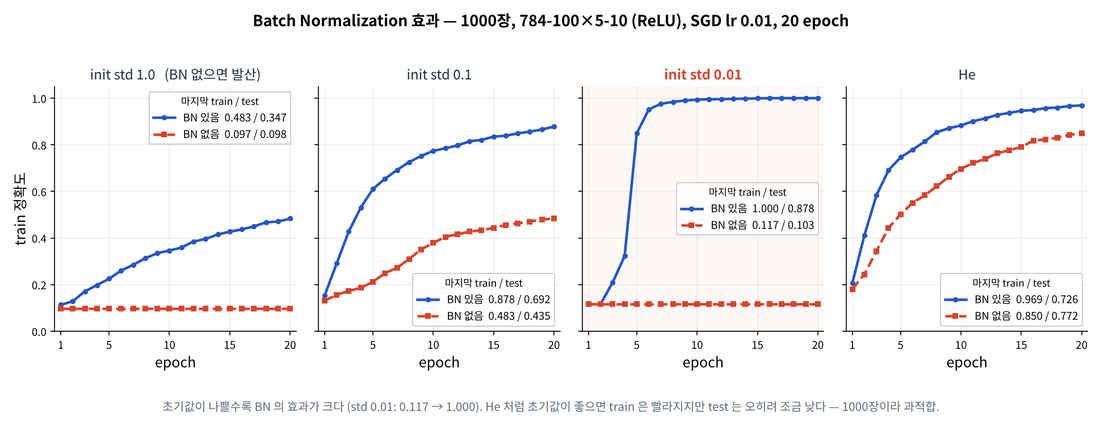

std 0.01 은 BN 없이는 전혀 학습되지 않지만(0.117) BN 을 넣으면 train **1.000** 까지 올라갑니다. BN 은 **초기화에 덜 민감**하게 만들고, 큰 학습률에서도 안정적이어서 학습을 빠르게 합니다. (1000장만 썼으므로 train 과 test 의 차이는 5교시 주제인 과적합입니다.)

#### ⚠️ 자주 하는 실수

- 추론 때 `train_flg=True` 로 — 배치 구성에 따라 결과가 달라지고, 한 장이면 출력이 0. `predict` 는 기본 `train_flg=False`.
- `x.mean()` (축 없음) — 전체 평균 하나가 됩니다. 특성마다 `axis=0`.
- running 통계를 추론 때 갱신 — 갱신은 **학습 모드에서만**.
- γ, β 를 옵티마이저에 넘기지 않음 — `params` 에 넣어야 학습됩니다 (`MultiLayerNet` 은 gamma{i}, beta{i} 로 넣음).

#### 📌 4교시 정리

- BN: 미니배치 열마다 평균 0 · 분산 1 → γ, β 로 조정. 학습 땐 배치 통계, 추론 땐 running 평균.
- backward: $d\beta = \sum$dout, $d\gamma = \sum \hat x\,$dout, dx 의 열 합 = 0.
- 효과: 초기화 둔감, 빠르고 안정적인 학습. Affine → **BN** → ReLU.

## 5교시 — 과적합

**과적합(overfitting)** 은 모델이 학습 데이터를 **외워 버려** 처음 보는 데이터에서는 성능이 떨어지는 현상입니다. 데이터가 적고 모델이 클수록 잘 일어납니다. 일부러 재현해 봅니다: MNIST **300장**만으로 784-100×6-10 (파라미터 약 13만 개) 을 학습합니다.

> 🎬 **애니메이션** [D4-5 과적합](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html#d4-5)  
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html#t5)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
X300, t300 = X_train[:300], t_train[:300]
net_plain = MultiLayerNet(784, [100] * 6, 10)
h_plain = fit(net_plain, SGD(lr=0.1), X300, t300, epochs=200, X_val=X_test, t_val=t_test, eval_every=5)
print(f"200 epoch: train {h_plain['train_acc'][-1]:.3f}  test {h_plain['val_acc'][-1]:.3f}")

**문제 5-1** 마지막 train/test 정확도의 차이(일반화 간극)와, test 손실이 가장 낮았던 epoch 을 구하세요.

In [ ]:
gap_plain = ____
best_loss_epoch = ____

In [ ]:
print(f"간극 {gap_plain:.3f},  test 손실 최저 epoch {best_loss_epoch},  test 손실 25 epoch {h_plain['val_loss'][4]:.2f} → 200 epoch {h_plain['val_loss'][-1]:.2f}")
assert np.isclose(h_plain["train_acc"][-1], 1.0) and abs(h_plain["val_acc"][-1] - 0.786) < 0.005 and gap_plain > 0.2
assert h_plain["val_loss"][-1] > h_plain["val_loss"][4]; print("✅ train 은 100%, test 손실은 오히려 증가")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(h_plain["epoch"], h_plain["train_acc"], label="train"); ax[0].plot(h_plain["epoch"], h_plain["val_acc"], label="test")
ax[0].fill_between(h_plain["epoch"], h_plain["val_acc"], h_plain["train_acc"], alpha=.15); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h_plain["epoch"], h_plain["val_loss"], color="tab:red"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test loss"); ax[1].grid(alpha=.3)
plt.show()

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACmdhcF9wbGFpbiA9IGhfcGxhaW5bInRyYWluX2FjYyJdWy0xXSAtIGhf"
    "cGxhaW5bInZhbF9hY2MiXVstMV0KYmVzdF9sb3NzX2Vwb2NoID0gaF9wbGFpblsiZXBvY2giXVtpbnQobnAuYXJn"
    "bWluKGhfcGxhaW5bInZhbF9sb3NzIl0pKV0="
).decode("utf-8"))

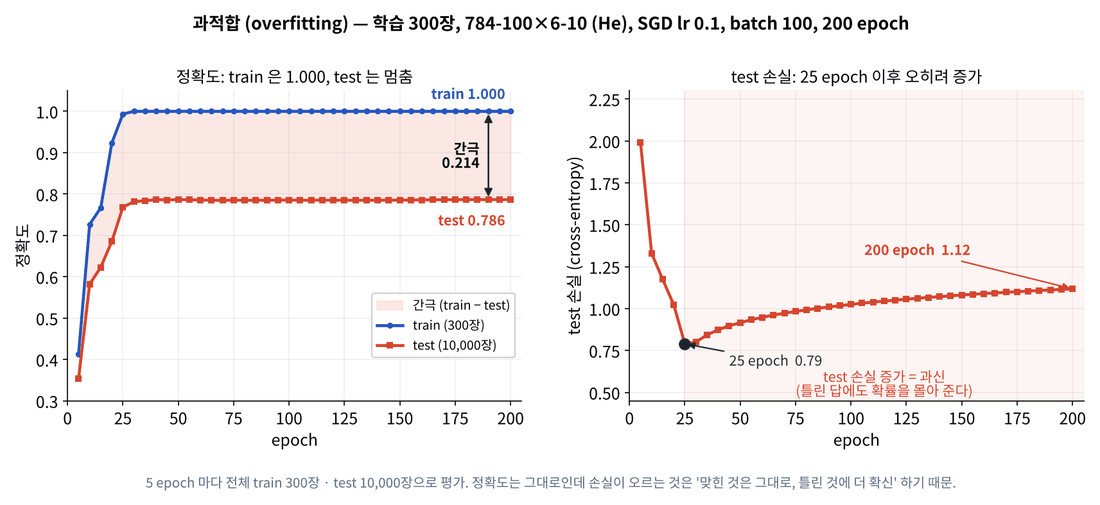

정확도만 보면 test 가 0.786 에서 **멈춘** 것 같지만, test **손실**은 계속 **올라갑니다**. 학습 데이터를 완벽히 맞히려고 가중치가 커지면서, 틀리는 test 샘플에 점점 더 **확신을 갖고** 틀리기 때문입니다 (cross-entropy 는 확신하며 틀릴수록 큰 벌점 — Day 2).

### 무엇이 과적합을 줄이나

**문제 5-2** 같은 모델을 데이터 **3000장**으로(iteration 수를 맞추려고 20 epoch), 그리고 300장에 **작은 모델** 784-100-10 으로 학습해 비교하세요.

In [ ]:
net_3000 = MultiLayerNet(784, [100] * 6, 10)
h_3000 = fit(net_3000, SGD(lr=0.1), ____, ____, epochs=20, X_val=X_test, t_val=t_test, eval_every=20)
net_small = ____
h_small = fit(net_small, SGD(lr=0.1), X300, t300, epochs=200, X_val=X_test, t_val=t_test, eval_every=200)

In [ ]:
rows = [("300장 · 6층", h_plain), ("3000장 · 6층", h_3000), ("300장 · 1층", h_small)]
for name, h in rows:
    print(f"{name:10s} train {h['train_acc'][-1]:.3f}  test {h['val_acc'][-1]:.3f}  간극 {h['train_acc'][-1] - h['val_acc'][-1]:.3f}")
assert h_3000["val_acc"][-1] > 0.9 and h_small["val_acc"][-1] > h_plain["val_acc"][-1]; print("✅ 데이터가 10배면 test 0.926")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACm5ldF8zMDAwID0gTXVsdGlMYXllck5ldCg3ODQsIFsxMDBdICogNiwg"
    "MTApCmhfMzAwMCA9IGZpdChuZXRfMzAwMCwgU0dEKGxyPTAuMSksIFhfdHJhaW5bOjMwMDBdLCB0X3RyYWluWzoz"
    "MDAwXSwgZXBvY2hzPTIwLCBYX3ZhbD1YX3Rlc3QsIHRfdmFsPXRfdGVzdCwgZXZhbF9ldmVyeT0yMCkKbmV0X3Nt"
    "YWxsID0gTXVsdGlMYXllck5ldCg3ODQsIFsxMDBdLCAxMCkKaF9zbWFsbCA9IGZpdChuZXRfc21hbGwsIFNHRChs"
    "cj0wLjEpLCBYMzAwLCB0MzAwLCBlcG9jaHM9MjAwLCBYX3ZhbD1YX3Rlc3QsIHRfdmFsPXRfdGVzdCwgZXZhbF9l"
    "dmVyeT0yMDAp"
).decode("utf-8"))

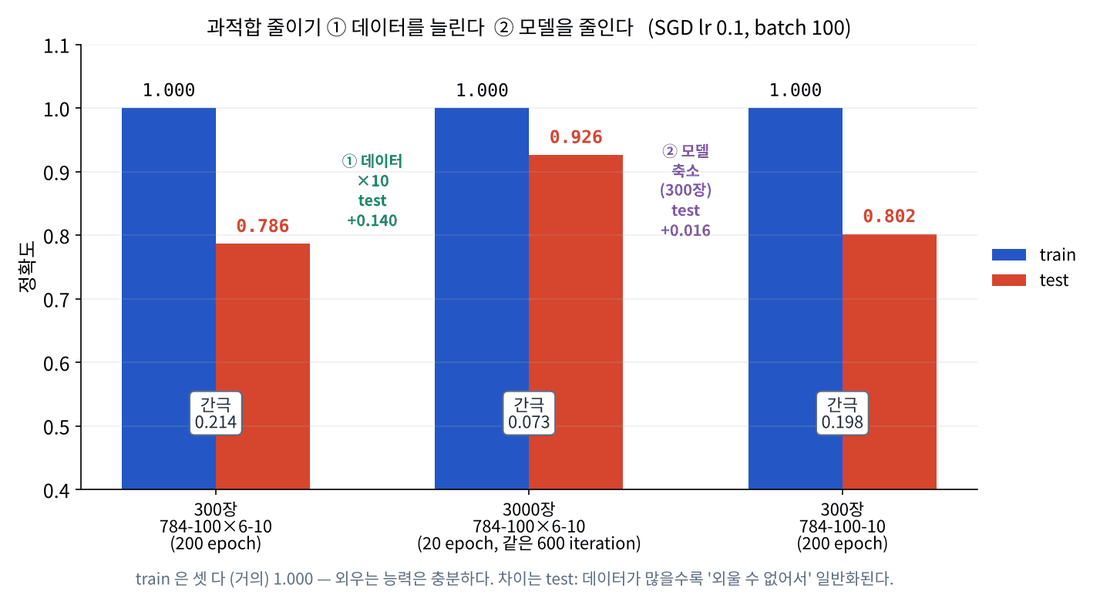

| 방법 | test | 비고 |
|---|---|---|
| 300장, 6층 | 0.786 | 과적합 |
| **데이터 10배** (3000장) | **0.926** | 가장 확실한 해결책 — 하지만 데이터는 비싸다 |
| 모델 줄이기 (1층) | 0.802 | 외울 능력 자체를 줄임 |
| 규제 (6교시) | 0.80 ~ 0.81 | 모델은 그대로, 학습에 제약 |

#### ⚠️ 자주 하는 실수

- test 데이터로 학습 상태를 보며 epoch · 모델을 고르기 — 그 순간 test 는 "본 데이터"가 됩니다 (7교시 validation).
- train 정확도만 보고 "잘 학습됐다" — 반드시 학습에 쓰지 않은 데이터로 평가.
- 정확도만 보기 — 과신은 손실 곡선에서 먼저 드러납니다.

#### 📌 5교시 정리

- 과적합: train ↑, test 정체, test **손실 증가**(과신). 데이터가 적고 모델이 클수록.
- 해결: 데이터 늘리기 > 모델 줄이기 / 규제 (6교시) / 조기 종료.

## 6교시 — 규제: weight decay · Dropout

모델 크기는 그대로 두고 **학습에 제약**을 걸어 과적합을 줄이는 방법을 **규제(regularization)** 라고 합니다.

> 🎬 **애니메이션** [D4-6 규제 — weight decay · Dropout](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html#d4-6)  
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html#t6)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### weight decay (L2 규제)

과적합된 모델은 가중치가 큰 경향이 있습니다. 손실에 **가중치 크기에 대한 벌점**을 더합니다.

$$L' = L + \frac{1}{2}\lambda \sum_{\text{모든 }W} \lVert W \rVert^2, \qquad \frac{\partial L'}{\partial W} = \frac{\partial L}{\partial W} + \lambda W$$

갱신식 $W \leftarrow W - \eta(\partial L/\partial W + \lambda W) = (1 - \eta\lambda)W - \eta\,\partial L/\partial W$ — 매 step 가중치를 $(1 - \eta\lambda)$ 배로 **조금씩 줄입니다**(decay). 편향 · γ · β 에는 걸지 않습니다. `MultiLayerNet` 의 `loss`, `gradient` 에 이미 이 두 줄이 들어 있습니다.

**문제 6-1** 모델의 L2 벌점 $\frac12\lambda\sum\lVert W\rVert^2$ 을 계산하는 함수를 만들고, `MultiLayerNet.loss` 의 결과와 일치하는지 확인하세요.

In [ ]:
def l2_penalty(net, lam):
    return ____

In [ ]:
net_w = MultiLayerNet(784, [100] * 6, 10, weight_decay_lambda=0.01)
L_with = net_w.loss(X300, t300); L_ce = net_w.lastLayer.forward(net_w.predict(X300), t300)
print(f"CE {L_ce:.4f} + 벌점 {l2_penalty(net_w, 0.01):.4f} = {L_with:.4f}")
assert np.isclose(L_with, L_ce + l2_penalty(net_w, 0.01)); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmRlZiBsMl9wZW5hbHR5KG5ldCwgbGFtKToKICAgIHJldHVybiAwLjUg"
    "KiBsYW0gKiBzdW0obnAuc3VtKG5ldC5wYXJhbXNbZiJXe2l9Il0gKiogMikgZm9yIGkgaW4gcmFuZ2UoMSwgbmV0"
    "Lm5fbGF5ZXJzICsgMSkp"
).decode("utf-8"))

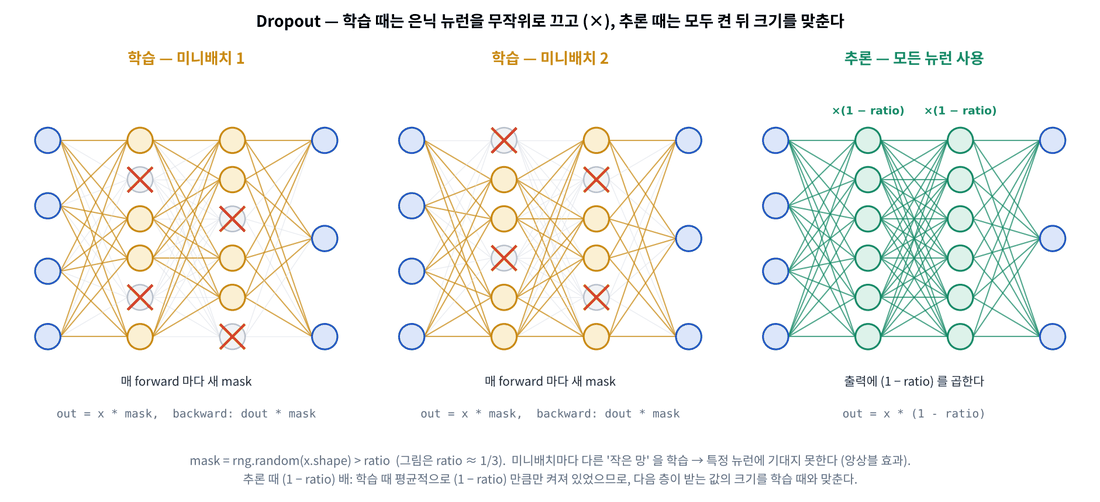

### Dropout

학습 때 은닉 뉴런을 **무작위로 꺼서**(출력 0) 매 미니배치마다 다른 "작은 네트워크"를 학습시킵니다. 특정 뉴런에 기대지 못하므로 더 견고한 특징을 배웁니다. 추론 때는 모든 뉴런을 쓰되, 학습 때 평균적으로 $(1 - \text{ratio})$ 만 켜져 있었으므로 출력을 **$(1 - \text{ratio})$ 배** 합니다 (여러 네트워크의 평균 효과, 앙상블).

역전파는 ReLU 의 mask 와 같습니다 — 꺼진 뉴런으로는 기울기도 흐르지 않습니다.

**문제 6-2** `Dropout` 계층을 완성하세요.

In [ ]:
class Dropout:
    def __init__(self, dropout_ratio=0.5, seed=0):
        self.ratio = dropout_ratio
        self.rng = np.random.default_rng(seed)
        self.mask = None

    def forward(self, x, train_flg=True):
        if train_flg:
            self.mask = ____     # True = 살림
            return ____
        return ____

    def backward(self, dout):
        return ____

In [ ]:
d = Dropout(0.2, seed=0); xd = np.ones((1000, 100))
out_tr, out_te = d.forward(xd, train_flg=True), d.forward(xd, train_flg=False)
print("학습: 켜진 비율", out_tr.mean().round(3), " / 추론: 출력", out_te[0, 0], "  — 평균이 같다")
assert abs(out_tr.mean() - 0.8) < 0.01 and np.allclose(out_te, 0.8) and np.array_equal(d.backward(xd), d.mask * 1.0); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACmNsYXNzIERyb3BvdXQ6CiAgICBkZWYgX19pbml0X18oc2VsZiwgZHJv"
    "cG91dF9yYXRpbz0wLjUsIHNlZWQ9MCk6CiAgICAgICAgc2VsZi5yYXRpbyA9IGRyb3BvdXRfcmF0aW8KICAgICAg"
    "ICBzZWxmLnJuZyA9IG5wLnJhbmRvbS5kZWZhdWx0X3JuZyhzZWVkKQogICAgICAgIHNlbGYubWFzayA9IE5vbmUK"
    "CiAgICBkZWYgZm9yd2FyZChzZWxmLCB4LCB0cmFpbl9mbGc9VHJ1ZSk6CiAgICAgICAgaWYgdHJhaW5fZmxnOgog"
    "ICAgICAgICAgICBzZWxmLm1hc2sgPSBzZWxmLnJuZy5yYW5kb20oeC5zaGFwZSkgPiBzZWxmLnJhdGlvICAgICAj"
    "IFRydWUgPSDsgrTrprwKICAgICAgICAgICAgcmV0dXJuIHggKiBzZWxmLm1hc2sKICAgICAgICByZXR1cm4geCAq"
    "ICgxLjAgLSBzZWxmLnJhdGlvKQoKICAgIGRlZiBiYWNrd2FyZChzZWxmLCBkb3V0KToKICAgICAgICByZXR1cm4g"
    "ZG91dCAqIHNlbGYubWFzaw=="
).decode("utf-8"))

**문제 6-3** 5교시와 같은 설정(300장, 6층, SGD 0.1, 200 epoch)에 weight decay λ = 0.01, Dropout 0.2 를 각각 적용해 비교하세요. (각 약 20초)

In [ ]:
net_wd = MultiLayerNet(784, [100] * 6, 10, weight_decay_lambda=____)
h_wd = fit(net_wd, SGD(lr=0.1), X300, t300, epochs=200, X_val=X_test, t_val=t_test, eval_every=5)
net_do = MultiLayerNet(784, [100] * 6, 10, use_dropout=____, dropout_ratio=0.2)
h_do = fit(net_do, SGD(lr=0.1), X300, t300, epochs=200, X_val=X_test, t_val=t_test, eval_every=5)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name, h in [("plain", h_plain), ("weight decay 0.01", h_wd), ("dropout 0.2", h_do)]:
    ax[0].plot(h["epoch"], h["val_acc"], label=f"{name} test"); ax[1].plot(h["epoch"], h["val_loss"], label=name)
    print(f"{name:18s} train {h['train_acc'][-1]:.3f}  test {h['val_acc'][-1]:.3f}  test 손실 {h['val_loss'][-1]:.2f}")
ax[0].set_ylabel("test accuracy"); ax[1].set_ylabel("test loss")
for a in ax: a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.show()
assert h_wd["val_acc"][-1] > h_plain["val_acc"][-1] and h_wd["val_loss"][-1] < h_plain["val_loss"][-1]
assert h_do["val_acc"][-1] > h_plain["val_acc"][-1]; print("✅ 두 규제 모두 test 정확도 상승")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACm5ldF93ZCA9IE11bHRpTGF5ZXJOZXQoNzg0LCBbMTAwXSAqIDYsIDEw"
    "LCB3ZWlnaHRfZGVjYXlfbGFtYmRhPTAuMDEpCmhfd2QgPSBmaXQobmV0X3dkLCBTR0QobHI9MC4xKSwgWDMwMCwg"
    "dDMwMCwgZXBvY2hzPTIwMCwgWF92YWw9WF90ZXN0LCB0X3ZhbD10X3Rlc3QsIGV2YWxfZXZlcnk9NSkKbmV0X2Rv"
    "ID0gTXVsdGlMYXllck5ldCg3ODQsIFsxMDBdICogNiwgMTAsIHVzZV9kcm9wb3V0PVRydWUsIGRyb3BvdXRfcmF0"
    "aW89MC4yKQpoX2RvID0gZml0KG5ldF9kbywgU0dEKGxyPTAuMSksIFgzMDAsIHQzMDAsIGVwb2Nocz0yMDAsIFhf"
    "dmFsPVhfdGVzdCwgdF92YWw9dF90ZXN0LCBldmFsX2V2ZXJ5PTUp"
).decode("utf-8"))

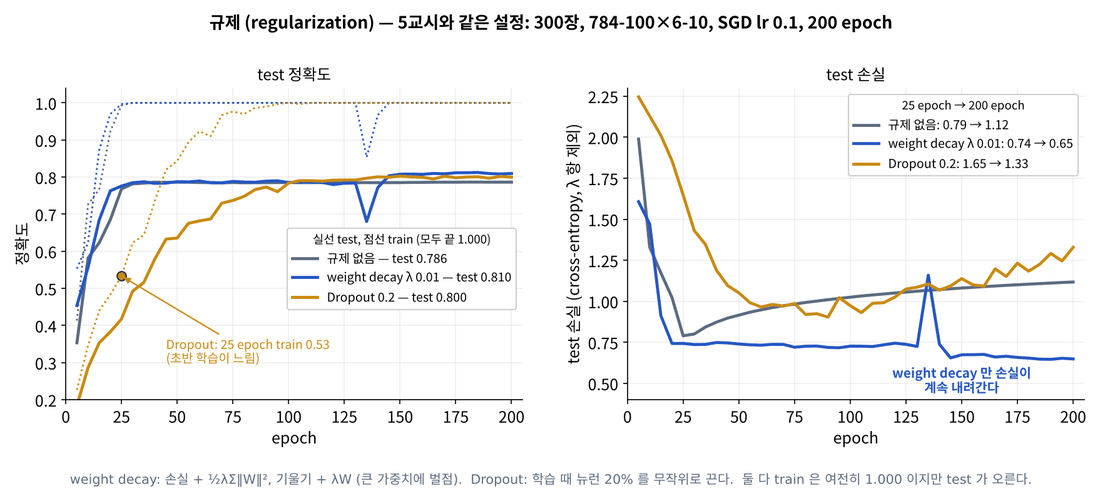

| | train | test | test 손실 (200 epoch) |
|---|---|---|---|
| 규제 없음 | 1.000 | 0.786 | 1.12 (증가) |
| weight decay λ = 0.01 | 1.000 | **0.810** | **0.65** (감소) |
| Dropout 0.2 | 1.000 | 0.800 | 1.33 |

- weight decay 는 가중치가 커지지 못하게 막아 **과신을 줄입니다** — test 손실이 계속 내려갑니다.
- Dropout 은 초반 학습이 느리지만(25 epoch train 0.53) 결국 test 정확도를 올립니다.
- λ 를 너무 키우면(0.1) 학습 데이터조차 못 맞혀 **과소적합**(train 0.767, test 0.641) — λ 도 7교시에서 고를 하이퍼파라미터입니다.

#### ⚠️ 자주 하는 실수

- 편향 · γ · β 에 weight decay — 보통 가중치 W 에만 겁니다.
- 손실에만 ½λΣW² 를 더하고 기울기에 λW 를 빼먹음 (또는 반대) — gradient check 로 잡힙니다.
- 추론 때도 Dropout 마스크를 씀 — `train_flg=False` 면 마스크 없이 (1 − ratio) 배.
- Dropout 을 출력층 뒤에 넣음 — 은닉층 활성화 뒤에만.

#### 📌 6교시 정리

- weight decay: 손실 + ½λΣW², 기울기 + λW → 가중치를 작게, 과신 감소.
- Dropout: 학습 때 무작위로 끄기 (mask), 추론 때 (1 − ratio) 배 → 앙상블 효과.
- 300장 · 6층: 0.786 → weight decay 0.810, Dropout 0.800. λ 가 크면 과소적합.

## 7교시 — 하이퍼파라미터 탐색

학습률, λ, 은닉층 크기, 배치 크기 … 사람이 정하는 값을 **하이퍼파라미터**라고 합니다. 이 값들을 **test 데이터로 고르면 안 됩니다** — test 에 맞춰 고른 순간 test 는 더 이상 "처음 보는 데이터"가 아니라서 성능을 부풀려 보고하게 됩니다.

> 🎬 **애니메이션** [D4-7 하이퍼파라미터 탐색](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html#d4-7)  
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html#t7)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

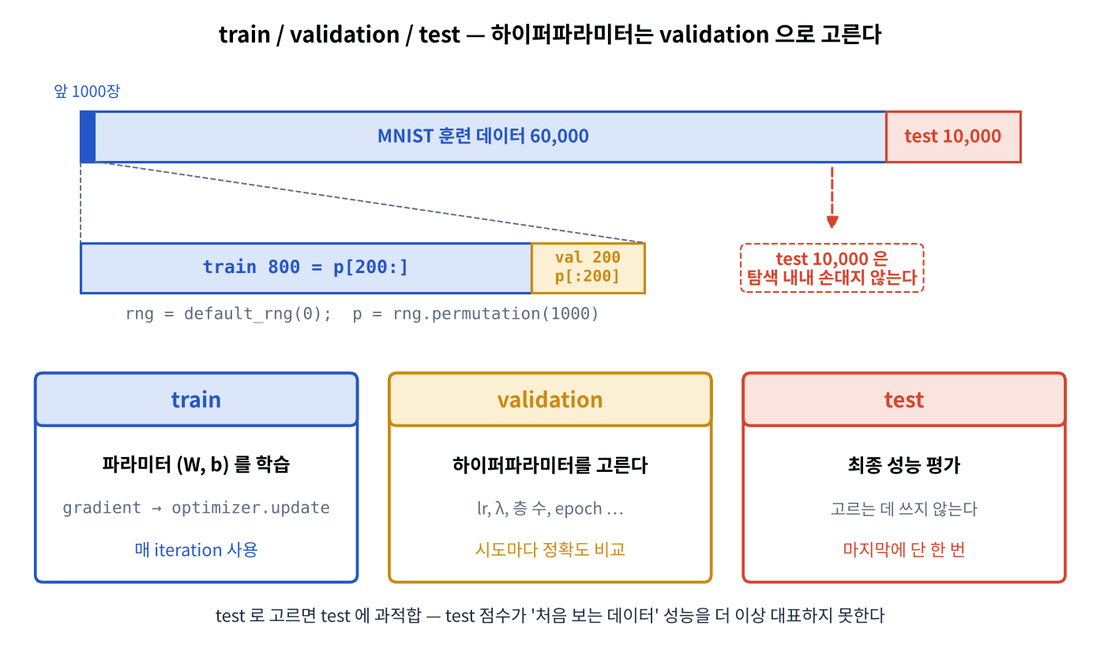

| 데이터 | 용도 | 몇 번 보나 |
|---|---|---|
| **train** | 파라미터(W, b) 학습 | 매 epoch |
| **validation** | 하이퍼파라미터 고르기 | 시도마다 |
| **test** | 최종 성능 보고 | **마지막에 한 번** |

**문제 7-1** MNIST 학습 데이터 1000장을 섞어 앞 20% (200장)를 validation, 나머지 800장을 train 으로 나누세요.

In [ ]:
rng7 = np.random.default_rng(0)
p = ____
X_val7, t_val7 = ____, t_train[:1000][p[:200]]
X_tr7, t_tr7 = X_train[:1000][p[200:]], ____

In [ ]:
assert X_val7.shape == (200, 784) and X_tr7.shape == (800, 784) and len(set(p[:200]) & set(p[200:])) == 0
print("✅ train", X_tr7.shape, " validation", X_val7.shape, " (test 10000장은 손대지 않음)")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACnJuZzcgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoMCkKcCA9IHJuZzcu"
    "cGVybXV0YXRpb24oMTAwMCkKWF92YWw3LCB0X3ZhbDcgPSBYX3RyYWluWzoxMDAwXVtwWzoyMDBdXSwgdF90cmFp"
    "bls6MTAwMF1bcFs6MjAwXV0KWF90cjcsIHRfdHI3ID0gWF90cmFpbls6MTAwMF1bcFsyMDA6XV0sIHRfdHJhaW5b"
    "OjEwMDBdW3BbMjAwOl1d"
).decode("utf-8"))

### 로그 스케일 랜덤 탐색

학습률은 0.001 과 0.002 의 차이보다 **0.001 과 0.01 의 차이**가 중요합니다. 그래서 지수를 균등하게 뽑습니다: $\eta = 10^{u},\; u \sim U(-4, 0)$ → 0.0001 ~ 1 을 자릿수마다 고르게.

또 **격자(grid) 탐색**보다 **랜덤 탐색**이 효율적입니다. 두 하이퍼파라미터 중 하나만 중요할 때, 3×3 격자는 중요한 축의 값을 3개만 보지만 랜덤 9번은 9개를 봅니다.

**문제 7-2 · 7-3** 30번 시도하는 탐색 루프를 완성하세요. 시도마다 lr 과 λ 를 뽑아 784-100-100-10 을 20 epoch 학습하고 validation 정확도를 기록합니다. (약 15초)

In [ ]:
def log_uniform(rng_, low, high):
    return ____

results = []                                                  # (val_acc, lr, λ, train_acc)
for trial in range(30):
    lr = log_uniform(rng7, -4, 0)
    lam = log_uniform(rng7, -6, -1)
    net = MultiLayerNet(784, [100, 100], 10, weight_decay_lambda=lam, seed=trial)
    h = fit(net, SGD(lr=lr), X_tr7, t_tr7, epochs=20, batch_size=100, seed=trial,
            X_val=____, t_val=____, eval_every=20)
    results.append((h["val_acc"][-1], lr, lam, h["train_acc"][-1]))

In [ ]:
top = sorted(results, reverse=True)
for va, lr, lam, tr in top[:5]:
    print(f"val {va:.3f}   lr {lr:.2e}   λ {lam:.2e}   train {tr:.3f}")
R = np.array(results)
sc = plt.scatter(R[:, 1], R[:, 2], c=R[:, 0], cmap="viridis", s=50); plt.colorbar(sc, label="val acc")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("learning rate"); plt.ylabel("weight decay"); plt.grid(alpha=.3); plt.show()
assert len(results) == 30 and abs(top[0][0] - 0.885) < 0.01 and 0.1 < top[0][1] < 0.7; print("✅ 좋은 lr 은 0.1 ~ 0.6 근처")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACmRlZiBsb2dfdW5pZm9ybShybmdfLCBsb3csIGhpZ2gpOgogICAgcmV0"
    "dXJuIDEwICoqIHJuZ18udW5pZm9ybShsb3csIGhpZ2gpCgpyZXN1bHRzID0gW10gICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMgKHZhbF9hY2MsIGxyLCDOuywgdHJhaW5fYWNjKQpmb3Ig"
    "dHJpYWwgaW4gcmFuZ2UoMzApOgogICAgbHIgPSBsb2dfdW5pZm9ybShybmc3LCAtNCwgMCkKICAgIGxhbSA9IGxv"
    "Z191bmlmb3JtKHJuZzcsIC02LCAtMSkKICAgIG5ldCA9IE11bHRpTGF5ZXJOZXQoNzg0LCBbMTAwLCAxMDBdLCAx"
    "MCwgd2VpZ2h0X2RlY2F5X2xhbWJkYT1sYW0sIHNlZWQ9dHJpYWwpCiAgICBoID0gZml0KG5ldCwgU0dEKGxyPWxy"
    "KSwgWF90cjcsIHRfdHI3LCBlcG9jaHM9MjAsIGJhdGNoX3NpemU9MTAwLCBzZWVkPXRyaWFsLAogICAgICAgICAg"
    "ICBYX3ZhbD1YX3ZhbDcsIHRfdmFsPXRfdmFsNywgZXZhbF9ldmVyeT0yMCkKICAgIHJlc3VsdHMuYXBwZW5kKCho"
    "WyJ2YWxfYWNjIl1bLTFdLCBsciwgbGFtLCBoWyJ0cmFpbl9hY2MiXVstMV0pKQ=="
).decode("utf-8"))

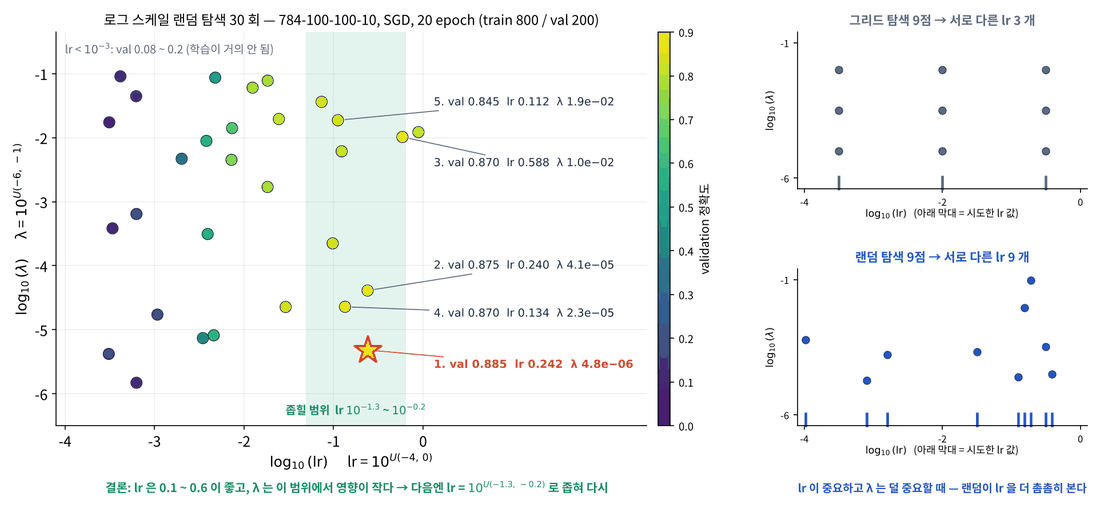

결과를 읽는 법:

- **lr 이 결정적**입니다. 0.1 ~ 0.6 근처는 val 0.84 ~ 0.885, lr 이 0.001 미만이면 20 epoch 으로는 거의 학습되지 않습니다 (val 0.1 근처).
- 이 범위에서 **λ 의 영향은 작습니다** (1e-6 이든 1e-2 이든 비슷).
- 다음 단계: lr 범위를 $10^{-1.3} \sim 10^{-0.2}$ 로 **좁혀** 다시 탐색하고, epoch 을 늘려 λ 를 세밀하게 봅니다. 이렇게 "넓게 → 좁게" 를 2~3번 반복합니다.
- 최종 하이퍼파라미터가 정해지면 train + validation 을 합쳐 다시 학습하고, **test 로 한 번만** 평가합니다.

#### ⚠️ 자주 하는 실수

- `lr = rng.uniform(1e-4, 1)` — 거의 모든 시도가 0.1 ~ 1 에 몰립니다. 지수를 뽑으세요.
- 탐색 중에 test 정확도를 보고 고르기 — validation 만.
- 처음부터 긴 epoch 으로 탐색 — 넓은 범위는 짧게 걸러 내고, 좁힌 뒤에 길게.

#### 📌 7교시 정리

- train (학습) / validation (선택) / test (최종 1회).
- 로그 스케일 + 랜덤 탐색, "넓게 → 좁게" 반복.
- 이 실험: lr 0.1 ~ 0.6 이 좋고 λ 영향은 작음 → 최고 val 0.885 (lr 0.242).

## 8교시 — 미니 프로젝트: 미니 프레임워크 `mynn.py`

Day 3 · 4 에서 만든 부품을 **재사용 가능한 모듈 하나**로 정리합니다. PyTorch · Keras 같은 프레임워크가 하는 일의 핵심이 바로 이것입니다 — 계층을 **리스트로 쌓고**, 파라미터를 **한곳에 모으고**, **학습 루프를 한 번만** 작성합니다.

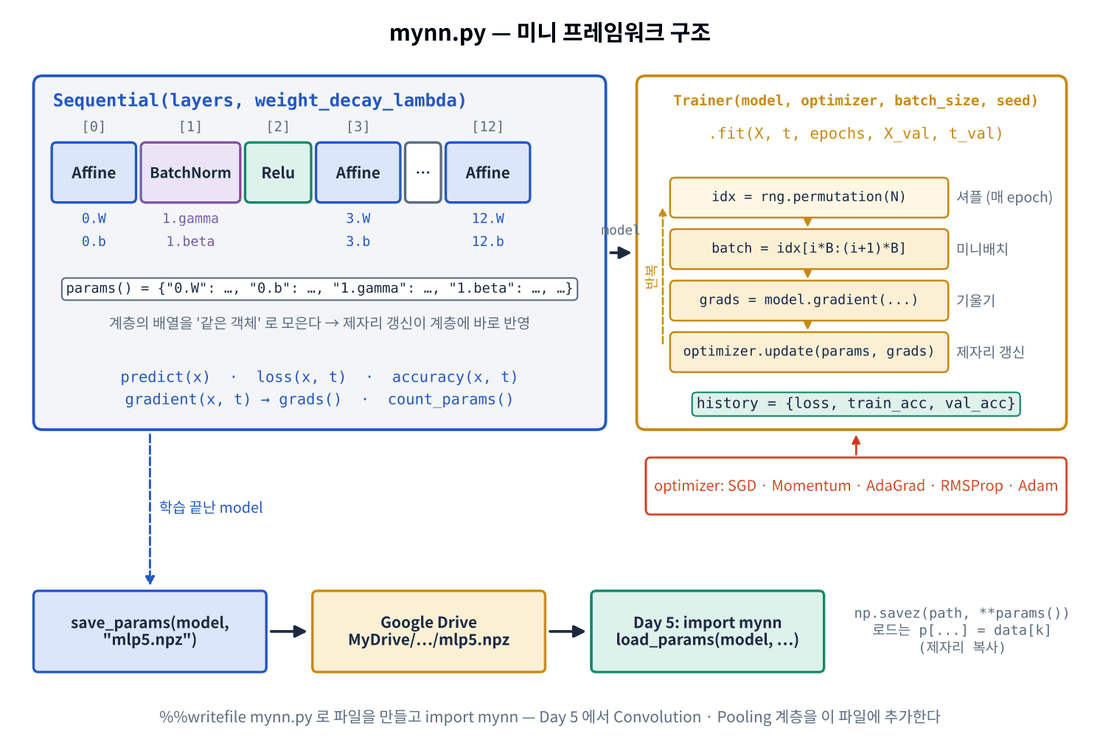

| 구성 | 역할 |
|---|---|
| 계층 `Affine(in, out, weight_init, seed)` · `Relu` · `Sigmoid` · `BatchNorm(size)` · `Dropout(ratio, seed)` | 각자 `params`, `grads` 딕셔너리와 `forward(x, train_flg)`, `backward(dout)` 를 가짐. BatchNorm 은 저장용 `buffers` (running 평균 · 분산) 도 가짐 |
| 옵티마이저 5종 | 2교시와 같음 — `update(params, grads)` |
| **`Sequential(layers, weight_decay_lambda)`** | 계층 리스트. `params()` 가 `{"0.W": …, "1.gamma": …}` 처럼 **계층의 배열 자체**를 모은다 (같은 객체 → 옵티마이저가 제자리 갱신하면 계층에 바로 반영) |
| **`Trainer(model, optimizer, batch_size, seed)`** | `fit(X, t, epochs, X_val, t_val)` — 셔플 → 배치 → gradient → update, history 기록 |
| `save_params` · `load_params` | 파라미터 + BN running 통계를 `.npz` 로 저장 / 제자리 복사로 불러오기 |

`%%writefile mynn.py` 는 셀 내용을 파일로 저장하는 Colab(IPython) 명령이고, `%%writefile -a` 는 파일 끝에 **덧붙입니다**. 파일을 만든 뒤 `import mynn` 으로 씁니다.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | `Sequential` 완성 | 20 |
| 2 | `Trainer.fit` · `load_params` 완성 | 20 |
| 3 | 5층 MLP (BN + He + Adam) 구성 · 학습, **test ≥ 0.97** | 30 |
| 4 | 저장 → 새 모델에 불러와 같은 정확도 확인, Drive 에 mynn.py 복사 | 20 |
| 5 | 결과 해석 (마크다운 답변) | 10 |

> 🎬 **애니메이션** [D4-8 미니 프레임워크](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/animation.html#d4-8)  
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day4/worksheet.html#t8)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### mynn.py ① — 함수 · 계층 · 옵티마이저 (주어진 코드: 오늘과 어제 만든 것을 정리한 것, 읽고 실행만 하세요)

In [ ]:
%%writefile mynn.py
# mynn.py — Neural Network 과정 미니 프레임워크 (Day 3 계층 + Day 4 학습 기법)
# Day 5 에서 Convolution · Pooling 계층을 이 파일에 추가합니다.
import numpy as np


# ───────────── 함수 ─────────────
def softmax(A):
    A = A - A.max(axis=-1, keepdims=True)
    expA = np.exp(A)
    return expA / expA.sum(axis=-1, keepdims=True)


def cross_entropy_error(y, t):
    if y.ndim == 1:
        y, t = y.reshape(1, -1), np.reshape(t, (1, -1))
    t = np.asarray(t)
    if t.size == y.size:
        t = t.argmax(axis=1)
    N = y.shape[0]
    return -np.sum(np.log(y[np.arange(N), t] + 1e-12)) / N


def numerical_gradient(f, x, h=1e-4):
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"])
    while not it.finished:
        idx = it.multi_index
        orig = x[idx]
        x[idx] = orig + h; fxh1 = f(x)
        x[idx] = orig - h; fxh2 = f(x)
        grad[idx] = (fxh1 - fxh2) / (2 * h)
        x[idx] = orig
        it.iternext()
    return grad


def rel_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-12)


def init_std(weight_init, n_in):
    """'he' → √(2/n_in), 'xavier' → √(1/n_in), 숫자 → 그대로"""
    if weight_init == "he":
        return np.sqrt(2.0 / n_in)
    if weight_init == "xavier":
        return np.sqrt(1.0 / n_in)
    return float(weight_init)


# ───────────── 계층 ─────────────
# 모든 계층: params (이름 → 배열), grads (같은 이름 → 기울기), forward(x, train_flg), backward(dout)
class Layer:
    def __init__(self):
        self.params, self.grads = {}, {}
        self.buffers = {}                  # 학습되지 않지만 저장해야 하는 값 (BatchNorm 의 running 평균 · 분산)

    def forward(self, x, train_flg=True):
        raise NotImplementedError

    def backward(self, dout):
        raise NotImplementedError


class Affine(Layer):
    def __init__(self, input_size, output_size, weight_init="he", seed=0):
        super().__init__()
        rng = np.random.default_rng(seed)
        self.params["W"] = init_std(weight_init, input_size) * rng.standard_normal((input_size, output_size))
        self.params["b"] = np.zeros(output_size)

    def forward(self, x, train_flg=True):
        self.x_shape = x.shape                    # Day 5: (N, C, H, W) 입력도 펼쳐서 받는다
        self.x = x.reshape(x.shape[0], -1)
        return self.x @ self.params["W"] + self.params["b"]

    def backward(self, dout):
        self.grads["W"] = self.x.T @ dout
        self.grads["b"] = dout.sum(axis=0)
        return (dout @ self.params["W"].T).reshape(self.x_shape)


class Relu(Layer):
    def forward(self, x, train_flg=True):
        self.mask = (x <= 0)
        out = x.copy()
        out[self.mask] = 0
        return out

    def backward(self, dout):
        dx = dout.copy()
        dx[self.mask] = 0
        return dx


class Sigmoid(Layer):
    def forward(self, x, train_flg=True):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1.0 - self.out)


class BatchNorm(Layer):
    def __init__(self, size, momentum=0.9, eps=1e-7):
        super().__init__()
        self.params["gamma"] = np.ones(size)
        self.params["beta"] = np.zeros(size)
        self.momentum, self.eps = momentum, eps
        self.buffers["running_mean"] = np.zeros(size)
        self.buffers["running_var"] = np.ones(size)

    def forward(self, x, train_flg=True):
        if train_flg:
            mu = x.mean(axis=0)
            self.xc = x - mu
            var = np.mean(self.xc ** 2, axis=0)
            self.std = np.sqrt(var + self.eps)
            self.xn = self.xc / self.std
            rm, rv = self.buffers["running_mean"], self.buffers["running_var"]
            rm[...] = self.momentum * rm + (1 - self.momentum) * mu        # 제자리 갱신
            rv[...] = self.momentum * rv + (1 - self.momentum) * var
        else:
            self.xn = (x - self.buffers["running_mean"]) / np.sqrt(self.buffers["running_var"] + self.eps)
        return self.params["gamma"] * self.xn + self.params["beta"]

    def backward(self, dout):
        N = dout.shape[0]
        self.grads["beta"] = dout.sum(axis=0)
        self.grads["gamma"] = np.sum(self.xn * dout, axis=0)
        dxn = self.params["gamma"] * dout
        return (N * dxn - dxn.sum(axis=0) - self.xn * np.sum(dxn * self.xn, axis=0)) / (N * self.std)


class Dropout(Layer):
    def __init__(self, ratio=0.5, seed=0):
        super().__init__()
        self.ratio = ratio
        self.rng = np.random.default_rng(seed)

    def forward(self, x, train_flg=True):
        if train_flg:
            self.mask = self.rng.random(x.shape) > self.ratio
            return x * self.mask
        return x * (1.0 - self.ratio)

    def backward(self, dout):
        return dout * self.mask


class SoftmaxWithLoss:
    def forward(self, x, t):
        self.t, self.y = t, softmax(x)
        self.loss = cross_entropy_error(self.y, t)
        return self.loss

    def backward(self, dout=1):
        N = self.y.shape[0]
        if self.t.size == self.y.size:
            return (self.y - self.t) / N * dout
        dx = self.y.copy()
        dx[np.arange(N), self.t] -= 1
        return dx / N * dout


# ───────────── 옵티마이저 ─────────────
class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr

    def update(self, params, grads):
        for k in params:
            params[k] -= self.lr * grads[k]


class Momentum:
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr, self.momentum, self.v = lr, momentum, None

    def update(self, params, grads):
        if self.v is None:
            self.v = {k: np.zeros_like(p) for k, p in params.items()}
        for k in params:
            self.v[k] = self.momentum * self.v[k] - self.lr * grads[k]
            params[k] += self.v[k]


class AdaGrad:
    def __init__(self, lr=0.01):
        self.lr, self.h = lr, None

    def update(self, params, grads):
        if self.h is None:
            self.h = {k: np.zeros_like(p) for k, p in params.items()}
        for k in params:
            self.h[k] += grads[k] ** 2
            params[k] -= self.lr * grads[k] / (np.sqrt(self.h[k]) + 1e-7)


class RMSProp:
    def __init__(self, lr=0.01, decay=0.99):
        self.lr, self.decay, self.h = lr, decay, None

    def update(self, params, grads):
        if self.h is None:
            self.h = {k: np.zeros_like(p) for k, p in params.items()}
        for k in params:
            self.h[k] = self.decay * self.h[k] + (1 - self.decay) * grads[k] ** 2
            params[k] -= self.lr * grads[k] / (np.sqrt(self.h[k]) + 1e-7)


class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999):
        self.lr, self.beta1, self.beta2 = lr, beta1, beta2
        self.m, self.v, self.t = None, None, 0

    def update(self, params, grads):
        if self.m is None:
            self.m = {k: np.zeros_like(p) for k, p in params.items()}
            self.v = {k: np.zeros_like(p) for k, p in params.items()}
        self.t += 1
        for k in params:
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * grads[k]
            self.v[k] = self.beta2 * self.v[k] + (1 - self.beta2) * grads[k] ** 2
            m_hat = self.m[k] / (1 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1 - self.beta2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + 1e-7)

### 과제 1 — `Sequential` (20점)

- `params()`: 계층 번호 `i` 와 파라미터 이름을 점으로 이어 `"0.W"` 같은 키를 만든다.
- `grads()`: 같은 키로 기울기를 모은다. 이름이 `"W"` 이면 weight decay 기울기 $\lambda W$ 를 더한다 (6교시).
- `predict()`: 계층을 차례로 `forward(x, train_flg)`.
- `gradient()`: 순전파(손실) → 손실 계층 backward → 계층을 **반대 순서로** backward → `grads()`.

In [ ]:
%%writefile -a mynn.py


# ───────────── 모델 · 학습 ─────────────
class Sequential:
    def __init__(self, layers, weight_decay_lambda=0.0):
        self.layers = layers
        self.loss_layer = SoftmaxWithLoss()
        self.weight_decay_lambda = weight_decay_lambda

    def params(self):
        """{'0.W': 배열, '0.b': 배열, '1.gamma': …} — 계층의 배열을 그대로(같은 객체) 모은다"""
        return {____: p for i, layer in enumerate(self.layers) for name, p in layer.params.items()}

    def grads(self):
        g = {}
        for i, layer in enumerate(self.layers):
            for name, d in layer.grads.items():
                if name == "W" and self.weight_decay_lambda:
                    d = d + ____     # weight decay 기울기 λW
                g[f"{i}.{name}"] = d
        return g

    def predict(self, x, train_flg=False):
        for layer in self.layers:
            x = ____
        return x

    def loss(self, x, t, train_flg=False):
        L = self.loss_layer.forward(self.predict(x, train_flg), t)
        if self.weight_decay_lambda:
            L += 0.5 * self.weight_decay_lambda * sum(np.sum(l.params["W"] ** 2) for l in self.layers if "W" in l.params)
        return L

    def accuracy(self, x, t, batch_size=1000):
        correct = 0
        for i in range(0, len(x), batch_size):
            correct += np.sum(self.predict(x[i:i + batch_size]).argmax(axis=1) == t[i:i + batch_size])
        return correct / len(x)

    def gradient(self, x, t):
        self.loss(x, t, train_flg=True)
        dout = self.loss_layer.backward(1)
        for layer in ____:
            dout = ____
        return self.grads()

    def count_params(self):
        return sum(p.size for p in self.params().values())

    def state(self):
        """저장용 — params + buffers (BatchNorm running 평균 · 분산)"""
        s = dict(self.params())
        s.update({f"{i}.{name}": b for i, layer in enumerate(self.layers) for name, b in layer.buffers.items()})
        return s

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACiUld3JpdGVmaWxlIC1hIG15bm4ucHkKCgojIOKUgOKUgOKUgOKUgOKU"
    "gOKUgOKUgOKUgOKUgOKUgOKUgOKUgOKUgCDrqqjrjbggwrcg7ZWZ7Iq1IOKUgOKUgOKUgOKUgOKUgOKUgOKUgOKU"
    "gOKUgOKUgOKUgOKUgOKUgApjbGFzcyBTZXF1ZW50aWFsOgogICAgZGVmIF9faW5pdF9fKHNlbGYsIGxheWVycywg"
    "d2VpZ2h0X2RlY2F5X2xhbWJkYT0wLjApOgogICAgICAgIHNlbGYubGF5ZXJzID0gbGF5ZXJzCiAgICAgICAgc2Vs"
    "Zi5sb3NzX2xheWVyID0gU29mdG1heFdpdGhMb3NzKCkKICAgICAgICBzZWxmLndlaWdodF9kZWNheV9sYW1iZGEg"
    "PSB3ZWlnaHRfZGVjYXlfbGFtYmRhCgogICAgZGVmIHBhcmFtcyhzZWxmKToKICAgICAgICAiIiJ7JzAuVyc6IOuw"
    "sOyXtCwgJzAuYic6IOuwsOyXtCwgJzEuZ2FtbWEnOiDigKZ9IOKAlCDqs4TsuLXsnZgg67Cw7Je07J2EIOq3uOuM"
    "gOuhnCjqsJnsnYAg6rCd7LK0KSDrqqjsnYDri6QiIiIKICAgICAgICByZXR1cm4ge2Yie2l9LntuYW1lfSI6IHAg"
    "Zm9yIGksIGxheWVyIGluIGVudW1lcmF0ZShzZWxmLmxheWVycykgZm9yIG5hbWUsIHAgaW4gbGF5ZXIucGFyYW1z"
    "Lml0ZW1zKCl9CgogICAgZGVmIGdyYWRzKHNlbGYpOgogICAgICAgIGcgPSB7fQogICAgICAgIGZvciBpLCBsYXll"
    "ciBpbiBlbnVtZXJhdGUoc2VsZi5sYXllcnMpOgogICAgICAgICAgICBmb3IgbmFtZSwgZCBpbiBsYXllci5ncmFk"
    "cy5pdGVtcygpOgogICAgICAgICAgICAgICAgaWYgbmFtZSA9PSAiVyIgYW5kIHNlbGYud2VpZ2h0X2RlY2F5X2xh"
    "bWJkYToKICAgICAgICAgICAgICAgICAgICBkID0gZCArIHNlbGYud2VpZ2h0X2RlY2F5X2xhbWJkYSAqIGxheWVy"
    "LnBhcmFtc1siVyJdICAgICAjIHdlaWdodCBkZWNheSDquLDsmrjquLAgzrtXCiAgICAgICAgICAgICAgICBnW2Yi"
    "e2l9LntuYW1lfSJdID0gZAogICAgICAgIHJldHVybiBnCgogICAgZGVmIHByZWRpY3Qoc2VsZiwgeCwgdHJhaW5f"
    "ZmxnPUZhbHNlKToKICAgICAgICBmb3IgbGF5ZXIgaW4gc2VsZi5sYXllcnM6CiAgICAgICAgICAgIHggPSBsYXll"
    "ci5mb3J3YXJkKHgsIHRyYWluX2ZsZykKICAgICAgICByZXR1cm4geAoKICAgIGRlZiBsb3NzKHNlbGYsIHgsIHQs"
    "IHRyYWluX2ZsZz1GYWxzZSk6CiAgICAgICAgTCA9IHNlbGYubG9zc19sYXllci5mb3J3YXJkKHNlbGYucHJlZGlj"
    "dCh4LCB0cmFpbl9mbGcpLCB0KQogICAgICAgIGlmIHNlbGYud2VpZ2h0X2RlY2F5X2xhbWJkYToKICAgICAgICAg"
    "ICAgTCArPSAwLjUgKiBzZWxmLndlaWdodF9kZWNheV9sYW1iZGEgKiBzdW0obnAuc3VtKGwucGFyYW1zWyJXIl0g"
    "KiogMikgZm9yIGwgaW4gc2VsZi5sYXllcnMgaWYgIlciIGluIGwucGFyYW1zKQogICAgICAgIHJldHVybiBMCgog"
    "ICAgZGVmIGFjY3VyYWN5KHNlbGYsIHgsIHQsIGJhdGNoX3NpemU9MTAwMCk6CiAgICAgICAgY29ycmVjdCA9IDAK"
    "ICAgICAgICBmb3IgaSBpbiByYW5nZSgwLCBsZW4oeCksIGJhdGNoX3NpemUpOgogICAgICAgICAgICBjb3JyZWN0"
    "ICs9IG5wLnN1bShzZWxmLnByZWRpY3QoeFtpOmkgKyBiYXRjaF9zaXplXSkuYXJnbWF4KGF4aXM9MSkgPT0gdFtp"
    "OmkgKyBiYXRjaF9zaXplXSkKICAgICAgICByZXR1cm4gY29ycmVjdCAvIGxlbih4KQoKICAgIGRlZiBncmFkaWVu"
    "dChzZWxmLCB4LCB0KToKICAgICAgICBzZWxmLmxvc3MoeCwgdCwgdHJhaW5fZmxnPVRydWUpCiAgICAgICAgZG91"
    "dCA9IHNlbGYubG9zc19sYXllci5iYWNrd2FyZCgxKQogICAgICAgIGZvciBsYXllciBpbiByZXZlcnNlZChzZWxm"
    "LmxheWVycyk6CiAgICAgICAgICAgIGRvdXQgPSBsYXllci5iYWNrd2FyZChkb3V0KQogICAgICAgIHJldHVybiBz"
    "ZWxmLmdyYWRzKCkKCiAgICBkZWYgY291bnRfcGFyYW1zKHNlbGYpOgogICAgICAgIHJldHVybiBzdW0ocC5zaXpl"
    "IGZvciBwIGluIHNlbGYucGFyYW1zKCkudmFsdWVzKCkpCgogICAgZGVmIHN0YXRlKHNlbGYpOgogICAgICAgICIi"
    "IuyggOyepeyaqSDigJQgcGFyYW1zICsgYnVmZmVycyAoQmF0Y2hOb3JtIHJ1bm5pbmcg7Y+J6regIMK3IOu2hOyC"
    "sCkiIiIKICAgICAgICBzID0gZGljdChzZWxmLnBhcmFtcygpKQogICAgICAgIHMudXBkYXRlKHtmIntpfS57bmFt"
    "ZX0iOiBiIGZvciBpLCBsYXllciBpbiBlbnVtZXJhdGUoc2VsZi5sYXllcnMpIGZvciBuYW1lLCBiIGluIGxheWVy"
    "LmJ1ZmZlcnMuaXRlbXMoKX0pCiAgICAgICAgcmV0dXJuIHM="
).decode("utf-8"))

### 과제 2 — `Trainer.fit` · `load_params` (20점)

Day 3 7교시 루프 그대로입니다: epoch 마다 섞고 → 배치를 자르고 → 기울기 → `optimizer.update(params, grads)`. `params` 는 루프 밖에서 **한 번** 모아 두면 됩니다 (같은 배열 객체이므로). `load_params` 는 저장된 값을 **제자리 복사**합니다.

In [ ]:
%%writefile -a mynn.py


class Trainer:
    def __init__(self, model, optimizer, batch_size=100, seed=0):
        self.model, self.optimizer, self.batch_size = model, optimizer, batch_size
        self.rng = np.random.default_rng(seed)
        self.history = {"loss": [], "train_acc": [], "val_acc": []}

    def fit(self, X, t, epochs=1, X_val=None, t_val=None, verbose=True):
        N = len(X)
        iters_per_epoch = max(N // self.batch_size, 1)
        params = self.model.params()
        for epoch in range(1, epochs + 1):
            idx = ____
            for i in range(iters_per_epoch):
                batch = ____
                grads = ____
                ____
                self.history["loss"].append(float(self.model.loss_layer.loss))
            self.history["train_acc"].append(self.model.accuracy(X, t))
            if X_val is not None:
                self.history["val_acc"].append(self.model.accuracy(X_val, t_val))
            if verbose:
                val = f"  val {self.history['val_acc'][-1]:.4f}" if X_val is not None else ""
                print(f"epoch {epoch:3d}  loss {np.mean(self.history['loss'][-iters_per_epoch:]):.4f}  "
                      f"train {self.history['train_acc'][-1]:.4f}{val}")
        return self.history


def save_params(model, path):
    np.savez(path, **model.state())


def load_params(model, path):
    data = np.load(path)
    for k, p in model.state().items():
        p[...] = ____                  # 제자리 복사 — 계층 · 옵티마이저와의 연결 유지

In [ ]:
import importlib, mynn
importlib.reload(mynn)                     # 파일을 고친 뒤 다시 실행해도 새 내용이 반영되게
print("mynn.py", os.path.getsize("mynn.py"), "bytes —", [n for n in dir(mynn) if n[0].isupper()])

# 확인: 작은 모델 gradient check (BN · Dropout(0) · weight decay 포함)
small = mynn.Sequential([mynn.Affine(784, 10, seed=1), mynn.BatchNorm(10), mynn.Relu(), mynn.Dropout(0.0),
                         mynn.Affine(10, 10, seed=2)], weight_decay_lambda=0.1)
Xs8, ts8 = X_train[:5], t_train[:5]
g_bp, P8 = small.gradient(Xs8, ts8), small.params()
g_num = {k: mynn.numerical_gradient(lambda _: small.loss(Xs8, ts8, train_flg=True), P8[k]) for k in P8}
for k in P8:
    print(f"{k:8s} 상대 오차 {mynn.rel_error(g_bp[k], g_num[k]):.1e}   |기울기| 최대 {np.abs(g_num[k]).max():.1e}")

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACiUld3JpdGVmaWxlIC1hIG15bm4ucHkKCgpjbGFzcyBUcmFpbmVyOgog"
    "ICAgZGVmIF9faW5pdF9fKHNlbGYsIG1vZGVsLCBvcHRpbWl6ZXIsIGJhdGNoX3NpemU9MTAwLCBzZWVkPTApOgog"
    "ICAgICAgIHNlbGYubW9kZWwsIHNlbGYub3B0aW1pemVyLCBzZWxmLmJhdGNoX3NpemUgPSBtb2RlbCwgb3B0aW1p"
    "emVyLCBiYXRjaF9zaXplCiAgICAgICAgc2VsZi5ybmcgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoc2VlZCkKICAg"
    "ICAgICBzZWxmLmhpc3RvcnkgPSB7Imxvc3MiOiBbXSwgInRyYWluX2FjYyI6IFtdLCAidmFsX2FjYyI6IFtdfQoK"
    "ICAgIGRlZiBmaXQoc2VsZiwgWCwgdCwgZXBvY2hzPTEsIFhfdmFsPU5vbmUsIHRfdmFsPU5vbmUsIHZlcmJvc2U9"
    "VHJ1ZSk6CiAgICAgICAgTiA9IGxlbihYKQogICAgICAgIGl0ZXJzX3Blcl9lcG9jaCA9IG1heChOIC8vIHNlbGYu"
    "YmF0Y2hfc2l6ZSwgMSkKICAgICAgICBwYXJhbXMgPSBzZWxmLm1vZGVsLnBhcmFtcygpCiAgICAgICAgZm9yIGVw"
    "b2NoIGluIHJhbmdlKDEsIGVwb2NocyArIDEpOgogICAgICAgICAgICBpZHggPSBzZWxmLnJuZy5wZXJtdXRhdGlv"
    "bihOKQogICAgICAgICAgICBmb3IgaSBpbiByYW5nZShpdGVyc19wZXJfZXBvY2gpOgogICAgICAgICAgICAgICAg"
    "YmF0Y2ggPSBpZHhbaSAqIHNlbGYuYmF0Y2hfc2l6ZTooaSArIDEpICogc2VsZi5iYXRjaF9zaXplXQogICAgICAg"
    "ICAgICAgICAgZ3JhZHMgPSBzZWxmLm1vZGVsLmdyYWRpZW50KFhbYmF0Y2hdLCB0W2JhdGNoXSkKICAgICAgICAg"
    "ICAgICAgIHNlbGYub3B0aW1pemVyLnVwZGF0ZShwYXJhbXMsIGdyYWRzKQogICAgICAgICAgICAgICAgc2VsZi5o"
    "aXN0b3J5WyJsb3NzIl0uYXBwZW5kKGZsb2F0KHNlbGYubW9kZWwubG9zc19sYXllci5sb3NzKSkKICAgICAgICAg"
    "ICAgc2VsZi5oaXN0b3J5WyJ0cmFpbl9hY2MiXS5hcHBlbmQoc2VsZi5tb2RlbC5hY2N1cmFjeShYLCB0KSkKICAg"
    "ICAgICAgICAgaWYgWF92YWwgaXMgbm90IE5vbmU6CiAgICAgICAgICAgICAgICBzZWxmLmhpc3RvcnlbInZhbF9h"
    "Y2MiXS5hcHBlbmQoc2VsZi5tb2RlbC5hY2N1cmFjeShYX3ZhbCwgdF92YWwpKQogICAgICAgICAgICBpZiB2ZXJi"
    "b3NlOgogICAgICAgICAgICAgICAgdmFsID0gZiIgIHZhbCB7c2VsZi5oaXN0b3J5Wyd2YWxfYWNjJ11bLTFdOi40"
    "Zn0iIGlmIFhfdmFsIGlzIG5vdCBOb25lIGVsc2UgIiIKICAgICAgICAgICAgICAgIHByaW50KGYiZXBvY2gge2Vw"
    "b2NoOjNkfSAgbG9zcyB7bnAubWVhbihzZWxmLmhpc3RvcnlbJ2xvc3MnXVstaXRlcnNfcGVyX2Vwb2NoOl0pOi40"
    "Zn0gICIKICAgICAgICAgICAgICAgICAgICAgIGYidHJhaW4ge3NlbGYuaGlzdG9yeVsndHJhaW5fYWNjJ11bLTFd"
    "Oi40Zn17dmFsfSIpCiAgICAgICAgcmV0dXJuIHNlbGYuaGlzdG9yeQoKCmRlZiBzYXZlX3BhcmFtcyhtb2RlbCwg"
    "cGF0aCk6CiAgICBucC5zYXZleihwYXRoLCAqKm1vZGVsLnN0YXRlKCkpCgoKZGVmIGxvYWRfcGFyYW1zKG1vZGVs"
    "LCBwYXRoKToKICAgIGRhdGEgPSBucC5sb2FkKHBhdGgpCiAgICBmb3IgaywgcCBpbiBtb2RlbC5zdGF0ZSgpLml0"
    "ZW1zKCk6CiAgICAgICAgcFsuLi5dID0gZGF0YVtrXSAgICAgICAgICAgICAgICAgICMg7KCc7J6Q66asIOuzteyC"
    "rCDigJQg6rOE7Li1IMK3IOyYte2LsOuniOydtOyggOyZgOydmCDsl7DqsrAg7Jyg7KeA"
).decode("utf-8"))

`0.b` (BN 바로 앞 Affine 의 편향) 만 상대 오차가 크게 보이지만, 기울기 자체가 1e-16 수준 — 참값이 **0** 이라 상대 오차가 의미 없는 경우입니다 (4교시: dx 의 열 합 = 0). 나머지는 모두 1e-8 이하로 통과입니다.

### 과제 3 — 5층 MLP 구성 · 학습 (30점)

784 → 100 → 100 → 100 → 100 → 10 (Affine 5개). 은닉층마다 **Affine(He) → BatchNorm → Relu**, 마지막은 Affine 하나. Affine 의 seed 는 1, 2, 3, 4, 5. Adam(lr 0.001), 배치 100, **5 epoch**, validation 자리에 test 를 넣어 epoch 마다 확인합니다 (약 15~40초).

In [ ]:
sizes = [784, 100, 100, 100, 100, 10]
layers = []
for i in range(5):
    layers.append(____)
    if i < 4:                                                    # 은닉층
        layers += [____, mynn.Relu()]
model = ____
print("계층", len(model.layers), "개 · 파라미터", f"{model.count_params():,}", "개 · 학습 전 손실", round(model.loss(X_train[:100], t_train[:100]), 3))

trainer = mynn.Trainer(model, ____, batch_size=100, seed=0)
history = ____

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(smooth(history["loss"]), lw=1); ax[0].set_yscale("log"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("loss"); ax[0].grid(alpha=.3)
ep = np.arange(1, len(history["val_acc"]) + 1)
ax[1].plot(ep, history["train_acc"], "o-", label="train"); ax[1].plot(ep, history["val_acc"], "s--", label="test")
ax[1].axhline(0.9694, color="gray", ls=":", label="Day 3 (0.9694)"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACnNpemVzID0gWzc4NCwgMTAwLCAxMDAsIDEwMCwgMTAwLCAxMF0KbGF5"
    "ZXJzID0gW10KZm9yIGkgaW4gcmFuZ2UoNSk6CiAgICBsYXllcnMuYXBwZW5kKG15bm4uQWZmaW5lKHNpemVzW2ld"
    "LCBzaXplc1tpICsgMV0sIHdlaWdodF9pbml0PSJoZSIsIHNlZWQ9aSArIDEpKQogICAgaWYgaSA8IDQ6ICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMg7J2A64uJ7Li1CiAgICAgICAg"
    "bGF5ZXJzICs9IFtteW5uLkJhdGNoTm9ybShzaXplc1tpICsgMV0pLCBteW5uLlJlbHUoKV0KbW9kZWwgPSBteW5u"
    "LlNlcXVlbnRpYWwobGF5ZXJzKQpwcmludCgi6rOE7Li1IiwgbGVuKG1vZGVsLmxheWVycyksICLqsJwgwrcg7YyM"
    "652866+47YSwIiwgZiJ7bW9kZWwuY291bnRfcGFyYW1zKCk6LH0iLCAi6rCcIMK3IO2VmeyKtSDsoIQg7IaQ7Iuk"
    "Iiwgcm91bmQobW9kZWwubG9zcyhYX3RyYWluWzoxMDBdLCB0X3RyYWluWzoxMDBdKSwgMykpCgp0cmFpbmVyID0g"
    "bXlubi5UcmFpbmVyKG1vZGVsLCBteW5uLkFkYW0obHI9MC4wMDEpLCBiYXRjaF9zaXplPTEwMCwgc2VlZD0wKQpo"
    "aXN0b3J5ID0gdHJhaW5lci5maXQoWF90cmFpbiwgdF90cmFpbiwgZXBvY2hzPTUsIFhfdmFsPVhfdGVzdCwgdF92"
    "YWw9dF90ZXN0KQ=="
).decode("utf-8"))

### 과제 4 — 저장하고 다시 불러오기 (20점)

학습한 모델을 저장하고, **다른 seed 로 새로 만든** 같은 구조의 모델에 불러와 정확도가 똑같은지 확인합니다. BN 의 running 통계까지 저장해야 추론 결과가 같습니다. 마지막으로 `mynn.py` 와 가중치를 Drive 에 복사해 Day 5 에서 씁니다.

In [ ]:
mynn.save_params(model, "day4_mlp.npz")

layers2 = []
for i in range(5):
    layers2.append(mynn.Affine(sizes[i], sizes[i + 1], seed=100 + i))     # 다른 seed
    if i < 4:
        layers2 += [mynn.BatchNorm(sizes[i + 1]), mynn.Relu()]
model2 = mynn.Sequential(layers2)
acc_before = model2.accuracy(X_test, t_test)
____
acc_after = model2.accuracy(X_test, t_test)
print(f"불러오기 전 {acc_before:.4f} → 후 {acc_after:.4f}   (원래 모델 {model.accuracy(X_test, t_test):.4f})")

drive_dir = "/content/drive/MyDrive/NN_course"
if os.path.isdir("/content/drive/MyDrive"):
    os.makedirs(drive_dir, exist_ok=True)
    for f in ["mynn.py", "day4_mlp.npz"]:
        shutil.copy(f, drive_dir)
    print("Drive 에 저장:", os.listdir(drive_dir))
else:
    print("Drive 가 연결되지 않아 복사를 건너뜁니다 (Colab 에서는 자동으로 저장됩니다)")

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSACm15bm4uc2F2ZV9wYXJhbXMobW9kZWwsICJkYXk0X21scC5ucHoiKQoK"
    "bGF5ZXJzMiA9IFtdCmZvciBpIGluIHJhbmdlKDUpOgogICAgbGF5ZXJzMi5hcHBlbmQobXlubi5BZmZpbmUoc2l6"
    "ZXNbaV0sIHNpemVzW2kgKyAxXSwgc2VlZD0xMDAgKyBpKSkgICAgICMg64uk66W4IHNlZWQKICAgIGlmIGkgPCA0"
    "OgogICAgICAgIGxheWVyczIgKz0gW215bm4uQmF0Y2hOb3JtKHNpemVzW2kgKyAxXSksIG15bm4uUmVsdSgpXQpt"
    "b2RlbDIgPSBteW5uLlNlcXVlbnRpYWwobGF5ZXJzMikKYWNjX2JlZm9yZSA9IG1vZGVsMi5hY2N1cmFjeShYX3Rl"
    "c3QsIHRfdGVzdCkKbXlubi5sb2FkX3BhcmFtcyhtb2RlbDIsICJkYXk0X21scC5ucHoiKQphY2NfYWZ0ZXIgPSBt"
    "b2RlbDIuYWNjdXJhY3koWF90ZXN0LCB0X3Rlc3QpCnByaW50KGYi67aI65+s7Jik6riwIOyghCB7YWNjX2JlZm9y"
    "ZTouNGZ9IOKGkiDtm4Qge2FjY19hZnRlcjouNGZ9ICAgKOybkOuemCDrqqjrjbgge21vZGVsLmFjY3VyYWN5KFhf"
    "dGVzdCwgdF90ZXN0KTouNGZ9KSIpCgpkcml2ZV9kaXIgPSAiL2NvbnRlbnQvZHJpdmUvTXlEcml2ZS9OTl9jb3Vy"
    "c2UiCmlmIG9zLnBhdGguaXNkaXIoIi9jb250ZW50L2RyaXZlL015RHJpdmUiKToKICAgIG9zLm1ha2VkaXJzKGRy"
    "aXZlX2RpciwgZXhpc3Rfb2s9VHJ1ZSkKICAgIGZvciBmIGluIFsibXlubi5weSIsICJkYXk0X21scC5ucHoiXToK"
    "ICAgICAgICBzaHV0aWwuY29weShmLCBkcml2ZV9kaXIpCiAgICBwcmludCgiRHJpdmUg7JeQIOyggOyepToiLCBv"
    "cy5saXN0ZGlyKGRyaXZlX2RpcikpCmVsc2U6CiAgICBwcmludCgiRHJpdmUg6rCAIOyXsOqysOuQmOyngCDslYrs"
    "lYQg67O17IKs66W8IOqxtOuEiOucgeuLiOuLpCAoQ29sYWIg7JeQ7ISc64qUIOyekOuPmeycvOuhnCDsoIDsnqXr"
    "kKnri4jri6QpIik="
).decode("utf-8"))

### 과제 5 — 결과 해석 (10점)

아래 셀에 답을 쓰세요.

1. Day 3 (784-100-10, std 0.01, SGD 0.1, 10 epoch) 은 test 0.9694, 오늘 모델은 5 epoch 에 0.975 를 넘었습니다. 오늘 배운 기법 중 어떤 것들이 기여했는지 세 가지 이상 쓰고 각각 한 줄로 이유를 설명하세요.
2. `Sequential.params()` 가 배열을 **복사하지 않고 그대로** 돌려주는 것이 왜 중요한가요? 복사본을 돌려주면 어떤 일이 생기나요?
3. `save_params` 가 γ, β 뿐 아니라 BN 의 running 평균 · 분산까지 저장해야 하는 이유는?

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4gKGEpIEhlIOy0iOq4sO2ZlCDigJQgUmVMVSDsuLXsnYQg7KeA64KY64+E"
    "IO2ZnOyEse2ZlCDrtoTsgrDsnbQg7Jyg7KeA65CY7Ja0IDXsuLXsnbTslrTrj4Qg7Iug7Zi47JmAIOq4sOyauOq4"
    "sOqwgCDsgrTslYQg7J6I7J2MIChzdGQgMC4wMSDsnbTrqbQg6rmK7J2AIOunneydgCDtlZnsirXsnbQg7Iuc7J6R"
    "65CY7KeAIOyViuydjCkuIChiKSBCYXRjaCBOb3JtYWxpemF0aW9uIOKAlCDrp6Qg7Li17J2YIOu2hO2PrOulvCDs"
    "oJXqt5ztmZTtlbQg7LSI6riw7ZmUIMK3IO2VmeyKteuloOyXkCDrjZwg66+86rCQ7ZWY6rOgIOu5oOultOqyjCDs"
    "iJjroLQuIChjKSBBZGFtIOKAlCDtjIzrnbzrr7jthLDrp4jri6Qg7ZWZ7Iq166Wg7J2EIOyhsOygiO2VmOqzoCDq"
    "tIDshLHsnYQg7I2o7IScIFNHRCDrs7Tri6Qg6rCZ7J2AIGl0ZXJhdGlvbiDsl5Ag7IaQ7Iuk7J2EIO2bqOyUrCDr"
    "uajrpqwg7KSE7J6ELiAoZCkg642UIOq5iuydgCDrqqjrjbgo7J2A64uJ7Li1IDTqsJwpIOKAlCDtkZztmITroKXs"
    "nbQg7Luk7KeQLiDrsJjrqbQg6rO87KCB7ZWp7J2AIDbrp4wg7J6l7J2YIOy2qeu2hO2VnCDrjbDsnbTthLAg642V"
    "67aE7JeQIO2BrOyngCDslYrsnYwodHJhaW4gMC45OTIgLyB0ZXN0IDAuOTc2KS4KMi4g7Ji17Yuw66eI7J207KCA"
    "64qUIHBhcmFtcyDrlJXshZTrhIjrpqzsnZgg67Cw7Je07J2EIOygnOyekOumrCgtPSnroZwg6rCx7Iug7ZWp64uI"
    "64ukLiDqt7gg67Cw7Je07J20IOqzhOy4teydtCBmb3J3YXJkIOyXkCDsk7DripQg67Cw7Je06rO8IOqwmeydgCDq"
    "sJ3ssrTsl6zslbwg6rCx7Iug7J20IOuqqOuNuOyXkCDrsJjsmIHrkKnri4jri6QuIOuzteyCrOuzuOydtOuptCDs"
    "mLXti7Drp4jsnbTsoIDripQg67O17IKs67O466eMIOuwlOq+uOqzoCDqs4TsuLXsnZgg6rCA7KSR7LmY64qUIOq3"
    "uOuMgOuhnOudvCDtlZnsirXsnbQg7KCE7ZiAIOuQmOyngCDslYrsirXri4jri6QgKERheSAzIOydmCAn7KCc7J6Q"
    "66asIOqwseyLoCcg6rO8IOqwmeydgCDsnbTsnKApLgozLiDstpTroaAodHJhaW5fZmxnPUZhbHNlKSDrlYwgQk4g"
    "7J2AIHJ1bm5pbmcg7Y+J6regIMK3IOu2hOyCsOycvOuhnCDsoJXqt5ztmZTtlanri4jri6QuIOydtOqyg+ydhCDs"
    "oIDsnqXtlZjsp4Ag7JWK7Jy866m0IOyDiCDrqqjrjbjsnZgg7LSI6rmD6rCSKO2Pieq3oCAwLCDrtoTsgrAgMSns"
    "nLzroZwg7KCV6rec7ZmU65CY7Ja0IO2VmeyKtSDrlYzsmYAg64uk66W4IOyeheugpSDrtoTtj6zqsIAg64uk7J2M"
    "IOy4teyXkCDrk6TslrTqsIDqs6Ag7KCV7ZmV64+E6rCAIO2BrOqyjCDrlqjslrTsp5Hri4jri6QuIO2VmeyKteuQ"
    "mOyngCDslYrripQg6rCS7J20652864+EIOuqqOuNuOydmCDsnbzrtoDsnbTrr4DroZwg7KCA7J6l7ZW07JW8IO2V"
    "qeuLiOuLpChidWZmZXJzKS4="
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    P = model.params()
    assert "0.W" in P and "1.gamma" in P and P["0.W"] is model.layers[0].params["W"]
    sq = mynn.Sequential([mynn.Affine(4, 3, seed=1)], weight_decay_lambda=0.5)
    gq = sq.gradient(np.ones((2, 4)), np.array([0, 1]))
    assert np.allclose(gq["0.W"], sq.layers[0].grads["W"] + 0.5 * sq.layers[0].params["W"])
    assert all(rel_error(g_bp[k], g_num[k]) < 1e-6 for k in g_num if np.abs(g_num[k]).max() > 1e-6)
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", e)
try:
    assert len(history["loss"]) == 5 * 600 and len(history["val_acc"]) == 5 and history["loss"][-1] < history["loss"][0]
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", e)
try:
    assert len(model.layers) == 13 and model.count_params() == 110_610
    assert history["val_acc"][-1] >= 0.97 and abs(model.accuracy(X_test, t_test) - history["val_acc"][-1]) < 1e-9
    score += 30; print(f"✅ 과제 3  +30   (test {history['val_acc'][-1]:.4f})")
except Exception as e: print("❌ 과제 3", e)
try:
    assert acc_before < 0.5 and abs(acc_after - model.accuracy(X_test, t_test)) < 1e-12
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", e)
print(f"\n자동 채점 {score} / 90  (과제 5 는 강사 채점 10점)")

### 🔎 더 알아보기 — Day 3 와 Day 4 비교

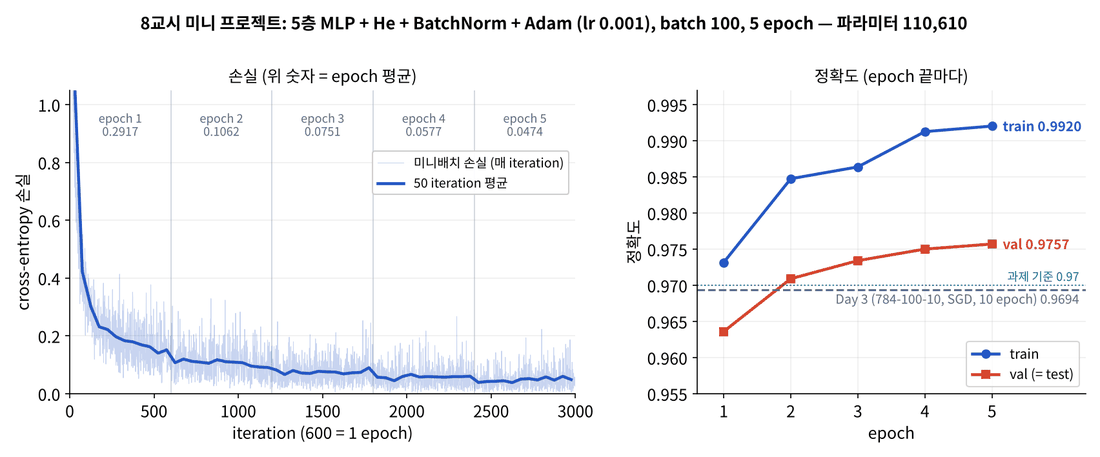

| | Day 3 | Day 4 |
|---|---|---|
| 모델 | 784-100-10 | 784-100×4-10 + BN |
| 초기화 | std 0.01 | He |
| 옵티마이저 | SGD 0.1 | Adam 0.001 |
| 학습 | 10 epoch | **5 epoch** |
| test | 0.9694 | **0.9757** |
| 파라미터 | 79,510 | 110,610 |

### 온디바이스 관점 — 학습 기법은 추론 비용을 늘리지 않는다

Adam · He 초기화 · Dropout · weight decay 는 **학습할 때만** 쓰입니다. 추론 때 모델은 여전히 행렬곱 + ReLU 이고, Dropout 은 (1 − ratio) 곱하기로, BN 은 고정된 $\gamma(x - \mu)/\sigma + \beta$ — 즉 **앞의 Affine 에 합쳐 넣을 수 있는** 선형 변환입니다. 아래 셀은 BN 을 Affine 에 접어 넣어(BN folding) 계층 수를 줄여도 결과가 같음을 보여 줍니다. TensorRT 같은 추론 엔진이 실제로 하는 최적화입니다.

In [ ]:
# BN folding: Affine(W, b) → BN(γ, β, μ, σ²)  ==  Affine(W', b'),  W' = W·γ/√(σ²+ε),  b' = (b − μ)·γ/√(σ²+ε) + β
folded = []
L_ = model.layers
for i in range(0, 12, 3):                                     # [Affine, BN, Relu] × 4
    A, B = L_[i], L_[i + 1]
    s = B.params["gamma"] / np.sqrt(B.buffers["running_var"] + B.eps)
    W2 = A.params["W"] * s; b2 = (A.params["b"] - B.buffers["running_mean"]) * s + B.params["beta"]
    folded += [(W2, b2), "relu"]
folded.append((L_[12].params["W"], L_[12].params["b"]))

def predict_folded(x):
    for item in folded:
        x = np.maximum(0, x) if item == "relu" else x @ item[0] + item[1]
    return x

acc_fold = np.mean(predict_folded(X_test).argmax(axis=1) == t_test)
print(f"원래 13계층 {model.accuracy(X_test, t_test):.4f}  →  BN 을 접어 넣은 9계층 {acc_fold:.4f}")

## 오늘의 정리

### 셀프 체크

- [ ] 비등방성 지형에서 SGD 가 지그재그하는 이유와 학습률 상한을 설명할 수 있다
- [ ] Momentum · AdaGrad · RMSProp · Adam 의 갱신식을 구현하고 차이를 한 줄씩 말할 수 있다
- [ ] 같은 값 초기화의 대칭 문제와 Xavier $\sqrt{1/n}$ · He $\sqrt{2/n}$ 의 근거를 설명할 수 있다
- [ ] BatchNorm 의 forward(학습 / 추론)와 backward 를 구현하고 gradient check 를 통과시켰다
- [ ] 과적합을 train/test 곡선과 test 손실로 진단할 수 있다
- [ ] weight decay 와 Dropout 을 구현하고 효과를 실험으로 확인했다
- [ ] train / validation / test 의 역할을 구분하고 로그 스케일 랜덤 탐색을 할 수 있다
- [ ] `mynn.py` 의 Sequential · Trainer 를 완성해 5층 MLP 로 test 0.97 이상을 얻고 Drive 에 저장했다

### 다음 주 월요일 (Day 5) 예고 — CNN 원리

MNIST 를 784 개짜리 **한 줄로 펼쳐서** 넣었습니다. 그러면 "이웃한 픽셀"이라는 공간 정보가 사라집니다. Day 5 는 이미지를 2D 그대로 다루는 **합성곱(Convolution)** 과 **풀링(Pooling)** 계층을 만들고 (**im2col** 로 합성곱을 행렬곱으로 바꾸는 트릭 포함), Drive 의 **`mynn.py` 를 import** 해 `Sequential` 에 넣어 CNN 으로 MNIST 를 학습합니다. 마지막으로 모델의 파라미터 수 · 연산량 · 메모리를 계산해 Vision 과정의 경량화로 이어집니다.

**Drive 의 `NN_course/mynn.py` 가 있는지 꼭 확인하세요.**